# Interim-report analysis: one peak done properly, then two detectors compared

On 3 November 2026 the demonstrator went through the peak fitting with us and set out what the interim report should contain (timestamps below refer to the recording of that session). This notebook does exactly that analysis, in his order, on the two background spectra we have.

* **Detector 1**, the ORTEC HPGe on the third floor read by a DSPEC-LF, background run `BkgRun5_Long` (3 to 7 September 2026, 3.88 days live).
* **Detector 2**, the Mirion HPGe in the basement read by a Lynx, background run of 12 to 15 October 2026 (2.94 days live), measured by another group.

His instructions, and where each is answered.

| Instruction (time in the recording) | Section |
|---|---|
| Fit one peak with a Gaussian of mean $\mu$, width $\sigma$ and amplitude $A$ on a background, and look at how the parameters are correlated (00:00–01:53) | 2, 3 |
| Prove that the statistical errors are believable: $A$ is a count, so its error should be close to $\sqrt N$, and a 0.01 % error on $\mu$ should make you suspicious (02:22–04:55) | 3 |
| Investigate the systematic errors from the choice of fit range, background model and peak shape (tail), for example by plotting the parameters against the window width (04:55–10:13) | 4 |
| Use simulated data with known parameters to find what the analysis technique itself does (10:13–11:15) | 5 |
| Do it for both detectors, which may behave differently (12:06) | 2–7 |
| Calibration curve with residuals, $\mu$ gives the calibration and $\sigma$ the resolution (14:56–15:27) | 6 |
| A table of every line with its abundance in counts per unit time for each background, and compare $\sigma$ (resolution) too (16:02–18:12) | 7 |
| Which background has the higher rates, and why (18:12–18:39) | 7 |
| Plot the two spectra so the comparison is clear, in the regions that matter, and correct for the different binning (13:00–14:08, 30:37) | 8 |
| Always quote fitted value, statistical error, systematic error and goodness of fit, with sensible significant figures (20:25–21:52) | 3, 4, 9 |

The comparison of a two-day and a four-day run of the Norway 2 sediment, done in notebook 2, is summarised in Section 10 for the report.

**Part 2 (Sections 11 to 19)** answers further questions that arose while writing the report, namely what the two file formats and their bin widths are, why the K-40 peak looks tilted, how our fit differs from InterSpec's, why the report had two K-40 rates, the Cs-137 line in the third-floor background, the stability of the Lynx, the numbers behind the plans, the double beta decay extension of the lab script, and the prediction of errors before fitting. Its own table of contents is at the start of Part 2.

Every analysis step starts with a cell that explains why it is needed, the physics or statistics behind it, how the method works and what would go wrong without it.

### The analysis as a chain of steps
Each step answers a question that the previous one raises, and the report follows the same order. Part 2 of the notebook (Sections 11 to 19) was added later to answer questions that arose while writing the report, so its sections are listed here at the step they belong to.

| Step | Question | What we do, and why this way | Sections | What it hands on |
|---|---|---|---|---|
| 1. Comparable spectra | What is in each file, and how can two detectors with different bin widths and live times be compared? | Read counts and live time, normalise to counts per keV per day for display, fit only raw channels | 1, 11 | spectra on a common footing |
| 2. Naming the peaks | Which peak is K-40, when the stored calibrations are wrong or absent? | Matched-filter search and pattern matching against known lines, because peaks are sparse and no prior calibration is trusted | 2 | a rough energy scale |
| 3. One peak done properly | What model, statistic and window give honest numbers for one peak? | Gaussian on a sloping line integrated over each channel, Poisson likelihood (not least squares or Neyman's $\chi^2$), window by the Barlow rule; the tilt explained, InterSpec compared | 3, 12, 13 | a fit procedure and its known weaknesses |
| 4. Testing the result | Are the errors believable, and what do our choices do to the answer? | Back-of-the-envelope errors, variation of window, background and shape, simulated peaks with a known truth | 3, 4, 5, 19 | positions from the tailed model, areas robust to 0.4 % |
| 5. Calibration and resolution | How does channel map to energy, how wide are the lines, and is the system stable? | Polynomial with an F-test and a per-line systematic, three-term resolution curve, five Lynx runs compared | 2, 6, 16 | energies, widths for fixed-shape fits |
| 6. Every line, both backgrounds | Which background is higher, and why? | Every line fitted at the same energy in both spectra with a fixed shape, rates and their ratio, zoomed plots in counts per keV per day | 7, 8, 14, 15 | the background that samples must be corrected for |
| 7. Counting time | What does counting half as long cost? | The same pot counted for 3.97 and 1.96 days, compared with the $\sqrt t$ prediction and simulations | 10, 17 | run lengths and the plans |
| Extension | What does the background say about double beta decay? | Currie's limit at 2039 keV | 18 | a first limit |

### Summary of results

| Question | Answer |
|---|---|
| K-40 with a Gaussian on a line | DSPEC (3rd floor) $A = 23\,189 \pm 158\,(\text{stat}) \pm 94\,(\text{sys})$ counts, $\mu = 7409.854 \pm 0.032 \pm 0.22$ channel, FWHM $2.093 \pm 0.012$ keV. Lynx (basement) $A = 500 \pm 28 \pm 22$ counts, $\mu = 8674.00 \pm 0.31 \pm 0.13$ channel, FWHM $2.10 \pm 0.11$ keV. |
| Are the statistical errors believable? | Yes. The area errors equal the counting estimate $\sqrt{A + 2B}$ within 2 % and the centre errors are 7 % (DSPEC) and 30 % (Lynx, more background) above the ideal $\sigma/\sqrt A$. 1000 simulated peaks per detector give pull widths of 0.98 to 1.03. |
| Should a 0.0004 % error on $\mu$ be trusted? | Not as the whole uncertainty. On the DSPEC peak the choice of peak shape moves $\mu$ by 0.22 channel (44 eV), seven times the statistical error, and simulated tailed peaks show that this is exactly what a Gaussian does to a peak with the measured tail. The area moves by only 0.4 %. |
| Fit window and background | The window is the narrowest in which a straight and a curved background agree: $\pm 7\sigma$ for DSPEC, $\pm 8\sigma$ for the weak Lynx peak. Over the defensible windows the area changes by 0.15 % (DSPEC) and 1.7 % (Lynx). |
| Calibration and resolution | DSPEC linear (13 lines, 43 eV per-line systematic), Lynx slightly curved (quadratic from IAEA-385). FWHM 1.30/2.00/2.64 keV (DSPEC) and 0.92/1.78/2.48 keV (Lynx) at 122/1332/2614.5 keV, Fano factors $0.086 \pm 0.011$ and $0.089 \pm 0.010$. |
| Which background is higher? | The third-floor DSPEC background, everywhere. Total 5.93 against 1.56 counts per second (40 to 2700 keV), K-40 38 times, Pb X-rays 46 times, radon daughters 4 to 17 times, cosmic-ray features (511 keV, above 2650 keV) only 1.7 to 2.7 times. The pattern points to much thicker shielding in the basement, with radon inside the shield and cosmic rays left over, not to a difference in detector size. |
| Two days against four (Norway 2, Lynx) | Gross-rate errors grew by 1.39 against the predicted 1.43, net-rate errors by 1.23 (predicted 1.25) because the background run is fixed, and simulated runs give 1.422. |
| Bins and file formats (Section 11) | Both files hold 16 384 channels, 0.197 keV wide (DSPEC, `.Chn`) and 0.168 keV wide (Lynx, `.csv`). Raw counts per channel would overstate the third-floor excess by 55 % (live time 32 %, bin width 17 %), so spectra are compared in counts per keV per day. |
| Why is the peak tilted? (Section 12) | The floor slopes ($-1.41 \pm 0.21$ counts per channel per keV, falling Compton continuum) and the peak has a low-energy tail (wing asymmetry $5.3 \pm 1.2$ %, charge trapping). With the tail in the model a step ($7.5 \pm 8.5$) and the Ac-228 neighbour ($0 \pm 120$ counts, 75 to 100 expected) are not needed. |
| Same as InterSpec? (Section 13) | Same model, different statistic. InterSpec minimises Neyman's $\chi^2$, which puts the floor about 1 count per channel too low. Strong peaks agree to 0.2 to 3 % in area and about 10 eV. For a 500-count peak Neyman is biased by $+1.3$ %, for 100 counts by $+8.8$ %, while the Poisson likelihood is unbiased, so ours is better for weak lines. |
| Two K-40 rates (Section 14) | Table 1 (width free) is the best value. Table 2 fixes the width to the resolution curve, which costs 6 % (1.1 statistical errors) for the Lynx K-40 peak. Ratio of the two floors 35 to 38. |
| Cs-137 in the background (Section 15) | $153 \pm 15$ counts per day on the third floor (10 standard deviations), below 22 in the basement, where it is 3.5 to 5.2 % of the sediment signal. |
| Lynx stability (Section 16) | Gain stable to about 20 ppm at K-40 over five runs and two weeks without a stabiliser. Widths consistent between runs ($p$ = 0.24 to 0.73). The K-40 width change between the Norway 2 runs is 1.6 standard deviations and not a gain drift. |
| Plans (Section 17) | Sealed on 17 November, a pot reaches 72 % of radon equilibrium by 24 November and 92 % by 1 December. Best sample to background time 4.4 (Cs-137) to 1.3 (radon daughters). A 10 % error in filling changes Pb-210 by 3.3 % and K-40 by 0.5 %. |
| Double beta decay (Section 18) | $T_{1/2}^{0\nu} > 5\times10^{19}$ (third floor) and $8\times10^{19}$ years (basement) per kg of germanium at 95 % confidence. |
| Predicted errors (Section 19) | All 30 line errors lie between $\sqrt{A+B}$ and $\sqrt{A+2B}$. Worst line Ra-226/U-235 at 186 keV in the basement (94 %), best K-40 on the third floor (0.7 %). |

## 1. Setup and data

### Which code is used
The reading, calibration and line-fitting functions come from `code/gamma_spec.py`, imported read-only, so that the calibrations here are the same as in the session notebooks. The single-peak fit of Sections 2 to 5, which is the centre of the demonstrator's questions, is written out below in about thirty lines, so that every step of it can be explained without reference to the module.

### Why the live time and the bin width both matter
To compare two spectra, the y-axis has to mean the same thing in both. Counts depend on how long the detector could record (live time) and on how wide each channel is in energy (bin width), and the two detectors differ in both. Dividing by the live time turns counts into a rate, and dividing by the bin width in keV turns counts per channel into counts per keV. Without the second step a narrow-channel spectrum would look lower by the ratio of the bin widths even if the physics were identical, which is the point the demonstrator made at the end of the session (30:37).

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

# ---------------- configuration
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "data" / "raw").is_dir())   # repository root
LAB = ROOT
OUT = ROOT
S2 = ROOT
D1, D2 = "DSPEC (3rd floor)", "Lynx (basement)"
BACKGROUNDS = {D1: ROOT / "data" / "raw" / "BkgRun5_Long.Chn",
               D2: ROOT / "data" / "raw" / "backround_run_hpge_12_10.csv"}
LYNX_REFERENCE = ROOT / "data" / "raw" / "thurs 15 oct - calibration sample 2 .csv"   # IAEA-385 on the Lynx
LYNX_OTHERS = [ROOT / "data" / "raw" / "Norway1_22_10.csv", ROOT / "data" / "raw" / "norway sample 2 - 22 oct 2026.csv"]
S2_SHAPE_FILE = ROOT / "results" / "session2" / "s2_IAEA-385_energy_calibration.json"               # Lynx tail from session 2
S3_RESULTS = ROOT / "results" / "session3"
N_TOYS = 1000
SEED = 20261103

sys.path.insert(0, str(ROOT / "code"))
sys.dont_write_bytecode = True                                        # write nothing into the session-2 folder
import gamma_spec as G
sys.dont_write_bytecode = False

FIG, RES = ROOT / "figures" / "interim", ROOT / "results" / "interim"
for folder in (FIG, RES):
    folder.mkdir(exist_ok=True)
# Computer Modern in the figures, the same typeface as the LaTeX report (the guidelines ask for a single font).
# Sizes are chosen so that, with the figure scaled to the text width of the report, labels print at about 8 to 9 pt.
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 13, "font.family": "serif",
                     "font.serif": ["cmr10"], "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True,
                     "axes.unicode_minus": True, "legend.fontsize": 10.5, "axes.titlesize": 12.5, "axes.labelsize": 13,
                     "xtick.labelsize": 11.5, "ytick.labelsize": 11.5, "pdf.fonttype": 42})
pd.set_option("display.width", 230)
import logging
logging.getLogger("fontTools").setLevel(logging.ERROR)                 # silence font-subsetting notes when saving PDFs
COL = {D1: "tab:blue", D2: "tab:red"}


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"ir_{name}.{ext}", dpi=200, bbox_inches="tight")


def table(df, decimals=3):
    print(df.round(decimals).to_string(index=False))


spec = {k: G.read_spectrum(p, label=k) for k, p in BACKGROUNDS.items()}
info = G.describe(spec.values())
table(info.drop(columns=["file", "end_from_real_time", "stored_cal"]), 4)
for k, s in spec.items():
    print(f"{k}: sha256 {s.sha256[:16]}..., stored calibration {s.stored_cal}")

            label    format  channels                    start  live_d  real_d  dead_pct  total_counts  rate_cps
DSPEC (3rd floor) ortec-chn     16384 Thu 03 Sep 2026 16:40:10  3.8826  3.8872    0.1176       2134012    6.3615
  Lynx (basement)  lynx-csv     16384 Mon 12 Oct 2026 16:28:44  2.9363  2.9369    0.0194        545987    2.1521
DSPEC (3rd floor): sha256 40e52f417ef1ba7b..., stored calibration (0.6763564944267273, 0.1966407299041748, 1.3927600406304919e-08)
Lynx (basement): sha256 e2c0784a6e618b90..., stored calibration (0.0, 1.0, 0.0)


## 2. Calibration of each detector, needed before any peak can be named

### Why first
The demonstrator's fit is done in channels, but to know that the peak is K-40 at 1460.8 keV, and later to compare the two detectors at the same energies, we need each detector's channel-to-energy map. Both are taken over from the session notebooks with the same code.

* **DSPEC.** The file's stored calibration is 3.3 keV low at 2614.5 keV, so we recalibrate from the background itself. A matched-filter search and pattern matching give a rough map, then the 13 natural reference lines are fitted (exponentially modified Gaussian, the tail length taken from a likelihood profile of this spectrum) and their positions fitted with a straight line or a quadratic chosen by an F-test.
* **Lynx.** The empty-shield background has only about seven usable lines, too few to see the slight curvature of the Lynx energy scale, so it borrows the quadratic term from the IAEA-385 spectrum taken with the same electronics (12 lines) and fits only offset and gain itself.

The full discussion is in the session notebooks (session 1 Section 7, session 2 Section 8). Here we need the result, and in Section 6 the residual plots.

**A note on order.** The calibration below already fits the reference lines with a tailed peak shape, and Section 3 then studies one peak with a plain Gaussian. In the logic of the analysis the order is the other way round: the rough calibration (pattern matching) is needed only to find K-40, the single-peak study of Sections 3 to 5 and 12 shows why positions must be taken from the tailed shape, and the final calibration of Section 6 uses that result. The code runs the calibration first only because every later section needs energies.

In [2]:
def tail_profile(s, rough, taus=np.round(np.arange(0.0, 1.01, 0.1), 2)):
    # deviance summed over the reference lines against the tail ratio tau = beta/sigma, parabola near the minimum
    D = np.array([G.fit_lines(s, rough, tail_ratio=t, step=0.0)[0].dev.sum() for t in taus])
    near = np.argsort(D)[:5]
    c2, c1, _ = np.polyfit(taus[near], D[near], 2)
    return float(-c1 / (2 * c2)), float(1 / np.sqrt(c2)), taus, D


def calibrate(s, tau, reference_cal=None):
    g0, g1, _, _ = G.auto_calibrate(s.counts)
    rough = G.linear_calibration(g0, g1)
    t, fits = G.fit_lines(s, rough, tail_ratio=tau, step=0.0)
    t["used"] = G.select_lines(t)
    u = t[t.used]
    lin = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, scale_by_chi2=False)
    quad = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, scale_by_chi2=False)
    F, pF = G.f_test(lin, quad)
    if pF < 0.01:
        cal, how = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, sys_keV="auto"), "quadratic"
    elif reference_cal is not None:
        cal, how = G.fit_calibration_borrowed_shape(u.position, u.sposition, u.E_ref, u.sE_ref, reference_cal), "curvature from IAEA-385"
    else:
        cal, how = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, sys_keV="auto"), "linear"
    t["E_fit"] = cal.energy(t.position)
    t["resid_keV"] = t.E_fit - t.E_ref
    t["sE_stat"] = lin.gain(t.position) * t.sposition
    return dict(rough=rough, lines=t, fits=fits, cal=cal, lin=lin, F=F, pF=pF, how=how)


rough1 = G.linear_calibration(*G.auto_calibrate(spec[D1].counts)[:2])
TAU = {}
TAU[D1], TAU_ERR1, taus1, Dtau1 = tail_profile(spec[D1], rough1)
TAU[D2] = json.loads(S2_SHAPE_FILE.read_text())["peak_shape"]["tail_ratio"]
print(f"tail ratio tau = beta/sigma: {D1} {TAU[D1]:.3f} +- {TAU_ERR1:.3f} (this spectrum), {D2} {TAU[D2]:.3f} (session 2, three spectra)")

lynx_ref = G.read_spectrum(LYNX_REFERENCE, label="IAEA-385 (Lynx)")
calib = {D1: calibrate(spec[D1], TAU[D1]), "IAEA-385 (Lynx)": calibrate(lynx_ref, TAU[D2])}
calib[D2] = calibrate(spec[D2], TAU[D2], calib["IAEA-385 (Lynx)"]["cal"])
cal = {k: calib[k]["cal"] for k in (D1, D2)}
for k, c in calib.items():
    poly = " + ".join(f"({a:.7g} +- {np.sqrt(c['cal'].C[j, j]):.2g}) x^{j}" for j, a in enumerate(c["cal"].a))
    print(f"{k:16s}: {int(c['lines'].used.sum())} lines, {c['how']}, F-test p = {c['pF']:.2g}, "
          f"per-line systematic {1000 * c['cal'].sys:.0f} eV\n{'':18s}E = {poly}")
for k in (D1, D2):
    print(f"{k}: bin width {float(cal[k].gain(cal[k].channel(1460.82))):.5f} keV per channel at 1460.8 keV, "
          f"range {float(cal[k].energy(0)):.1f} to {float(cal[k].energy(spec[k].n - 1)):.0f} keV")

tail ratio tau = beta/sigma: DSPEC (3rd floor) 0.493 +- 0.043 (this spectrum), Lynx (basement) 0.398 (session 2, three spectra)


DSPEC (3rd floor): 13 lines, linear, F-test p = 0.48, per-line systematic 43 eV
                  E = (0.2589994 +- 0.025) x^0 + (0.1971026 +- 4.1e-06) x^1
IAEA-385 (Lynx) : 12 lines, quadratic, F-test p = 3.8e-05, per-line systematic 79 eV
                  E = (0.09116691 +- 0.068) x^0 + (0.1683596 +- 2.3e-05) x^1 + (6.197686e-09 +- 1.4e-09) x^2
Lynx (basement) : 7 lines, curvature from IAEA-385, F-test p = 0.073, per-line systematic 174 eV
                  E = (0.09435763 +- 0.13) x^0 + (0.1683665 +- 1.5e-05) x^1 + (6.197686e-09 +- 0) x^2
DSPEC (3rd floor): bin width 0.19710 keV per channel at 1460.8 keV, range 0.3 to 3229 keV
Lynx (basement): bin width 0.16847 keV per channel at 1460.8 keV, range 0.1 to 2760 keV


## 3. One peak, fitted with a Gaussian on a straight background

### The model
In a region of interest (ROI) around one photopeak the expected number of counts in channel $i$ is
$$ f_i = A\int_{i-1/2}^{i+1/2}\frac{1}{\sqrt{2\pi}\,\sigma}\,\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right]\mathrm{d}x \;+\; b_0 + b_1\,(i - x_0), $$
the Gaussian the demonstrator wrote down (00:18), plus a straight-line background. The Gaussian is written with unit area, so $A$ is the number of counts in the peak, $\mu$ its centre and $\sigma$ its width, all three in channel units. Integrating it over each channel rather than taking its value at the channel centre makes it exact for any width. The channel content is a Poisson count, so the parameters are found by maximising the Poisson likelihood, which is the same as minimising the deviance
$$ D = 2\sum_i\left[f_i - n_i + n_i\ln\frac{n_i}{f_i}\right]. $$
Least squares with $\sigma_i^2 = n_i$ (Neyman's $\chi^2$) would put the background about one count per channel too low and bias the area with it, which matters for a weak peak (Section 13 measures this). For a good model $D$ follows a $\chi^2$ distribution with (channels minus parameters) degrees of freedom, so it is also the goodness of fit.

### Uncertainties and correlations
Near its minimum $-\ln L$ is a parabola in the parameters, and its curvature matrix (the Fisher information) is $I = J^\mathsf{T}\,\mathrm{diag}(1/f)\,J$ with $J_{ik} = \partial f_i/\partial p_k$. Its inverse is the covariance matrix $C$. The diagonal gives the statistical errors and $C_{kl}/\sqrt{C_{kk}C_{ll}}$ the correlations (01:28).

### Which window
The ROI is centred on the peak with the same width on each side (07:14), starting from $\mu \pm 7\sigma$. A Gaussian contains $1 - 10^{-11}$ of its area within $7\sigma$, and flanks of about $4.5\sigma$ on each side should be enough to fix a straight background. Whether they are is tested, not assumed. We also fit a quadratic background in the same window, and if the two background models disagree by more than statistics allow (the Barlow criterion of Section 4), the background is not yet pinned down by the flanks and the window is widened in steps until they agree. The window is therefore the narrowest one in which the answer no longer depends on the background model, which is a quantitative answer to the demonstrator's question "why did you choose this range?" (06:10).

### Which peak
K-40 at 1460.8 keV, a single γ line with no cascade partner (so no coincidence summing), the strongest isolated line in both backgrounds and the one that matters most for the sediments. Its only known neighbour is a weak Ac-228 line at 1459.1 keV (0.5 % of its area in detector 1, session 1).

Two questions that this section raises are answered in Part 2. Why the measured peak looks tilted, and which of the possible causes (sloping continuum, step, tail, Ac-228) are real, is Section 12. How this fit compares with InterSpec's, and why the Poisson likelihood is preferred to least squares, is Section 13.

In [3]:
SQ2 = np.sqrt(2.0)


def gauss_bins(x, mu, sigma):
    # fraction of a unit-area Gaussian inside channel x, which spans x - 1/2 to x + 1/2
    return 0.5 * (special.erf((x + 0.5 - mu) / (SQ2 * sigma)) - special.erf((x - 0.5 - mu) / (SQ2 * sigma)))


def emg_bins(x, mu, sigma, beta):
    # the same for a Gaussian with a low-energy exponential tail of length beta (used in Sections 4 and 5)
    return G.emg_cdf(x + 0.5, mu, sigma, beta) - G.emg_cdf(x - 0.5, mu, sigma, beta)


def model(p, x, x0, n_bkg, shape, tau):
    A, mu, sigma = p[0], p[1], p[2]
    bkg = sum(p[3 + j] * (x - x0)**j for j in range(n_bkg))
    peak = gauss_bins(x, mu, sigma) if shape == "gauss" else emg_bins(x, mu, sigma, tau * sigma)
    return A * peak + bkg


def fit_peak(counts, lo, hi, mu0, sigma0, n_bkg=2, shape="gauss", tau=0.0):
    # Poisson maximum-likelihood fit of one peak on a polynomial background (n_bkg = 1, 2, 3 terms)
    x = np.arange(lo, hi + 1, dtype=float)
    y = np.asarray(counts[lo:hi + 1], float)
    x0 = 0.5 * (lo + hi)
    side = np.r_[y[:5], y[-5:]]
    p0 = [max(y.sum() - side.mean() * len(y), 10.0), mu0, sigma0, side.mean()] + [0.0] * (n_bkg - 1)

    def dev_resid(p):
        f = np.clip(model(p, x, x0, n_bkg, shape, tau), 1e-12, None)
        d = 2 * (f - y + np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / f), 0.0))
        return np.sign(y - f) * np.sqrt(np.clip(d, 0, None))

    lb = [0.0, mu0 - 3 * sigma0, 0.3 * sigma0] + [-np.inf] * n_bkg
    ub = [np.inf, mu0 + 3 * sigma0, 3.0 * sigma0] + [np.inf] * n_bkg
    p = optimize.least_squares(dev_resid, np.clip(p0, np.array(lb) + 1e-9, np.array(ub) - 1e-9), bounds=(lb, ub),
                               x_scale="jac").x
    f = np.clip(model(p, x, x0, n_bkg, shape, tau), 1e-12, None)
    J = np.empty((len(x), len(p)))
    for k in range(len(p)):
        h = 1e-6 * max(abs(p[k]), 1e-3)
        pp, pm = p.copy(), p.copy()
        pp[k] += h
        pm[k] -= h
        J[:, k] = (model(pp, x, x0, n_bkg, shape, tau) - model(pm, x, x0, n_bkg, shape, tau)) / (2 * h)
    C = np.linalg.inv(J.T @ (J / f[:, None]))
    D = float(np.sum(dev_resid(p)**2))
    ndf = len(x) - len(p)
    position = G.emg_mode(p[1], p[2], tau * p[2]) if shape == "emg" else p[1]
    n_nonpositive = int(np.sum(model(p, x, x0, n_bkg, shape, tau) <= 0))   # channels the clip at 1e-12 would hide
    return dict(p=p, err=np.sqrt(np.diag(C)), C=C, x=x, y=y, f=f, x0=x0, D=D, chi2=float(np.sum((y - f)**2 / f)),
                ndf=ndf, pval=float(stats.chi2.sf(D, ndf)), position=position, n_bkg=n_bkg, shape=shape, tau=tau,
                n_nonpositive=n_nonpositive)


NAMES = ["A", "mu", "sigma", "b0", "b1", "b2"]
K40 = 1460.820
HALF_STEPS = [7, 8, 9, 10, 12]                                     # window half-widths tried, in units of sigma


def barlow(f1, f2, i):
    # shift of parameter i between two fits of (mostly) the same data, in units of sqrt(|var1 - var2|)
    d = f2["p"][i] - f1["p"][i]
    return d, d / np.sqrt(max(abs(f2["err"][i]**2 - f1["err"][i]**2), 1e-30))


peak, HALF, choice_log = {}, {}, []
for k in (D1, D2):
    row = calib[k]["lines"].set_index("E_ref").loc[K40]
    mu0, s0 = float(cal[k].channel(K40)), float(row.sigma_ch)
    first = fit_peak(spec[k].counts, int(mu0 - 7 * s0), int(mu0 + 7 * s0), mu0, s0)
    mu1, s1 = first["p"][1], first["p"][2]                         # recentre the window on the fitted peak
    for half in HALF_STEPS:
        lo, hi = int(round(mu1 - half * s1)), int(round(mu1 + half * s1))
        lin = fit_peak(spec[k].counts, lo, hi, mu1, s1, n_bkg=2)
        quad = fit_peak(spec[k].counts, lo, hi, mu1, s1, n_bkg=3)
        (dA, zA), (ds, zs) = barlow(lin, quad, 0), barlow(lin, quad, 2)
        ok = abs(zA) < 2 and abs(zs) < 2
        choice_log.append(dict(detector=k, half=half, A_lin=lin["p"][0], A_quad=quad["p"][0], dA=dA, dA_over_barlow=zA,
                               sigma_lin=lin["p"][2], sigma_quad=quad["p"][2], dsigma_over_barlow=zs,
                               D_lin=lin["D"], D_quad=quad["D"], models_agree=ok))
        if ok:
            peak[k], HALF[k] = lin, half
            break
choice_log = pd.DataFrame(choice_log)
print("choosing the window: the narrowest half-width at which linear and quadratic backgrounds agree (|shift| < 2 Barlow sigma)")
table(choice_log, 3)
print("adopted half-widths:", HALF)

rows = []
for k, r in peak.items():
    p, e = r["p"], r["err"]
    g = float(cal[k].gain(p[1]))
    rows.append(dict(detector=k, window=f"{int(r['x'][0])}-{int(r['x'][-1])}", A=p[0], sA=e[0], mu=p[1], smu=e[1], sigma=p[2],
                     ssigma=e[2], b0=p[3], b1=p[4], E_keV=float(cal[k].energy(p[1])), FWHM_keV=G.FWHM_PER_SIGMA * p[2] * g,
                     sFWHM_keV=G.FWHM_PER_SIGMA * e[2] * g, rate_cpd=86400 * p[0] / spec[k].live,
                     s_rate_cpd=86400 * e[0] / spec[k].live, D=r["D"], chi2=r["chi2"], ndf=r["ndf"], p_value=r["pval"]))
k40 = pd.DataFrame(rows)
table(k40, 4)
for k, r in peak.items():
    corr = r["C"] / np.outer(r["err"], r["err"])
    print(f"\n{k}: correlation matrix of (A, mu, sigma, b0, b1)")
    print(pd.DataFrame(corr, index=NAMES[:5], columns=NAMES[:5]).round(3).to_string())

choosing the window: the narrowest half-width at which linear and quadratic backgrounds agree (|shift| < 2 Barlow sigma)
         detector  half     A_lin    A_quad      dA  dA_over_barlow  sigma_lin  sigma_quad  dsigma_over_barlow  D_lin  D_quad  models_agree
DSPEC (3rd floor)     7 23189.278 23203.298  14.020           0.236      4.510       4.513               0.239 89.112  89.056          True
  Lynx (basement)     7   501.917   440.178 -61.738          -3.690      5.309       4.804              -3.083 85.775  75.510         False
  Lynx (basement)     8   499.853   479.151 -20.702          -1.265      5.285       5.104              -1.266 98.508  96.906          True
adopted half-widths: {'DSPEC (3rd floor)': 7, 'Lynx (basement)': 8}
         detector    window          A       sA        mu    smu  sigma  ssigma      b0      b1     E_keV  FWHM_keV  sFWHM_keV  rate_cpd  s_rate_cpd       D    chi2  ndf  p_value
DSPEC (3rd floor) 7378-7441 23189.2782 158.3204 7409.8539 0.0317 4.5098 

### Area or height: why the correlation depends on how the Gaussian is written
The demonstrator expected $A$ and $\sigma$ to be strongly correlated (01:28). That is true when the Gaussian is written with a **height** $h$, $f = h\,e^{-(x-\mu)^2/2\sigma^2}$, because the area is $h\sqrt{2\pi}\,\sigma$. A slightly wider fit can keep the same number of counts only by lowering the height, so $h$ and $\sigma$ move in opposite directions. Writing the Gaussian with unit area, as above, makes $A$ the area itself, and the area is fixed by the counts, not by the shape, so its correlation with $\sigma$ is small. Both descriptions are the same fit. The cell below converts the covariance to the height form with $h = A/(\sqrt{2\pi}\sigma)$ and the Jacobian of the transformation, $C_h = T\,C\,T^\mathsf{T}$, to show this. The lesson for the report is that "the parameters are correlated" is a statement about the parametrisation, and that the area form is the useful one, because the area is what forensics needs.

In [4]:
for k, r in peak.items():
    A, mu, sg = r["p"][:3]
    C3 = r["C"][:3, :3]
    h = A / (np.sqrt(2 * np.pi) * sg)
    T = np.array([[1 / (np.sqrt(2 * np.pi) * sg), 0, -A / (np.sqrt(2 * np.pi) * sg**2)], [0, 1, 0], [0, 0, 1]])
    Ch = T @ C3 @ T.T
    print(f"{k}: area form corr(A, sigma) = {C3[0, 2] / np.sqrt(C3[0, 0] * C3[2, 2]):+.3f};  "
          f"height form h = {h:.1f} +- {np.sqrt(Ch[0, 0]):.1f} counts/channel, corr(h, sigma) = {Ch[0, 2] / np.sqrt(Ch[0, 0] * Ch[2, 2]):+.3f}")

DSPEC (3rd floor): area form corr(A, sigma) = +0.111;  height form h = 2051.4 +- 17.2 counts/channel, corr(h, sigma) = -0.584
Lynx (basement): area form corr(A, sigma) = +0.316;  height form h = 37.7 +- 2.4 counts/channel, corr(h, sigma) = -0.559


### Are the statistical errors believable? A back-of-the-envelope check
The demonstrator's rule was to suspect small errors and to predict them roughly (02:32–04:29, 18:39).

* **The area.** $A$ is essentially a count. If the peak sat on nothing, its error would be $\sqrt A$. It sits on a background $B$ that has to be estimated from the flanks and subtracted, and estimating it from about as many channels as it lies under adds roughly its own variance again. So we expect
$$ \sigma_A \approx \sqrt{A + 2B}, $$
with $B$ the background counts under the peak, here within $\pm 2.5\sigma$ (99 % of the peak).
* **The centre.** Each of the $A$ counts is an independent measurement of $\mu$ with spread $\sigma$, so the mean of $A$ of them has error
$$ \sigma_\mu \approx \frac{\sigma}{\sqrt A}, $$
the best any method can do (the Cramér–Rao bound for a Gaussian). Background makes it slightly worse.
* **The width.** For a Gaussian sample the standard deviation is known to $\sigma/\sqrt{2A}$.

If the fit errors are close to these numbers, they are what counting statistics allow, neither more nor less. This does not make them the whole uncertainty. A 0.0004 % error on the K-40 position says only that the data are consistent with that position **under the assumed model**. Whether the model, the window and the background are right is a separate question with its own (systematic) uncertainty, which is the subject of Sections 4 and 5.

In [5]:
rows = []
for k, r in peak.items():
    A, mu, sg = r["p"][:3]
    x, f = r["x"], r["f"]
    bkg = model(np.r_[0.0, r["p"][1:]], x, r["x0"], r["n_bkg"], "gauss", 0.0)
    roi = np.abs(x - mu) <= 2.5 * sg
    B = float(bkg[roi].sum())
    rows.append(dict(detector=k, A=A, sqrt_A=np.sqrt(A), B_under_peak=B, expected_sA=np.sqrt(A + 2 * B), fit_sA=r["err"][0],
                     ratio_A=r["err"][0] / np.sqrt(A + 2 * B), expected_smu=sg / np.sqrt(A), fit_smu=r["err"][1],
                     ratio_mu=r["err"][1] / (sg / np.sqrt(A)), expected_ssigma=sg / np.sqrt(2 * A), fit_ssigma=r["err"][2],
                     rel_err_A_pct=100 * r["err"][0] / A, rel_err_mu_pct=100 * r["err"][1] / mu))
envelope = pd.DataFrame(rows)
table(envelope, 4)

         detector          A   sqrt_A  B_under_peak  expected_sA   fit_sA  ratio_A  expected_smu  fit_smu  ratio_mu  expected_ssigma  fit_ssigma  rel_err_A_pct  rel_err_mu_pct
DSPEC (3rd floor) 23189.2782 152.2803      828.6584     157.6280 158.3204   1.0044        0.0296   0.0317    1.0711           0.0209      0.0255         0.6827          0.0004
  Lynx (basement)   499.8531  22.3574      147.4092      28.1899  27.5849   0.9785        0.2364   0.3065    1.2966           0.1671      0.2788         5.5186          0.0035


### What the check shows
The area errors are what counting predicts. For the DSPEC peak $\sqrt{A} = 152$, the background under the peak is $B \approx 830$ counts, and $\sqrt{A + 2B} = 157.6$ against the fitted 158.3 (ratio 1.004). For the Lynx peak $\sqrt{A + 2B} = 28.2$ against the fitted 27.6 (0.98). So the fit's area error is a $\sqrt N$ counting error, enlarged slightly by the background, exactly as the demonstrator suggested it should be.

The centre errors are close to the ideal $\sigma/\sqrt A$, 7 % above it for the DSPEC peak, which sits 60 times above its background, and 30 % above for the Lynx peak, where the background is a third of the peak and the flanks carry more weight. The width errors are 22 % (DSPEC) and 67 % (Lynx) above the ideal $\sigma/\sqrt{2A}$, because the width is the parameter most entangled with the background level (correlation $-0.27$ and $-0.33$).

So the statistical errors are believable as statistical errors. The relative error of 0.0004 % on the DSPEC centre (0.03 channel out of 7410) is genuine, because 23 000 counts each locate the peak to within $\sigma = 4.5$ channels. What it does not include is any error of the model, and Sections 4 and 5 show that this is much larger.

The correlation matrices make the demonstrator's point about correlations concrete. In the area form, $A$ is almost uncorrelated with $\mu$ (below 0.02) and only weakly with $\sigma$ (0.11 and 0.32), while it is anti-correlated with the background level $b_0$ ($-0.18$ and $-0.35$), because counts assigned to the background are taken from the peak. In the height form, height and width are strongly anti-correlated ($-0.58$ and $-0.56$), as he expected.

## 4. Systematic errors: what our choices do to the answer

### Why
A systematic error comes from an assumption, not from the number of counts. If we knew the true shape of the peak and the background exactly, there would be none (08:42). We do not, so we vary each assumption over the range of reasonable choices and see how far the answer moves. The demonstrator named three choices (06:10–10:02).

1. **The fit window.** Section 3 chose the narrowest window in which the background is pinned down, but a slightly wider one would be just as defensible. A narrow window leaves too few channels to fix the background, a wide one lets the background's curvature and neighbouring features pull on the fit. We refit with half-widths from $3\sigma$ to $15\sigma$ and plot the parameters against the half-width (07:43). Where they are flat, the choice does not matter. The half-range of the values over the defensible windows (from $2\sigma$ below the adopted one up to $12\sigma$, never below $5\sigma$) is taken as the window systematic, which is the demonstrator's "range of values you get" (07:57).
2. **The background model.** A constant, a straight line or a parabola under the peak. A constant cannot follow the slope of the continuum and is shown only for illustration. The difference between the line and the parabola in the adopted window is the background systematic. The window scan shows both models at every window, which also makes the demonstrator's point that the window decides how much the background model matters (09:18).
3. **The peak shape.** A Gaussian assumes complete charge collection. Charge trapping in the crystal produces a low-energy tail, which session 1 and 2 found in both detectors. The exponentially modified Gaussian (EMG) adds a tail of length $\beta = \tau\sigma$ to the low side. With a tail the "position" of the peak is no longer one number, because the most probable value (mode), the mean and the centre of the underlying Gaussian differ. We compare the Gaussian $\mu$ with the EMG mode, the visible top of the peak.

### When is a shift a systematic and not just noise?
Two fits of the same data with slightly different windows share most of their counts, so their difference is far smaller than either statistical error, roughly $\sigma_\Delta = \sqrt{|\sigma_1^2 - \sigma_2^2|}$ (Barlow, 2002). It is exact for nested windows and approximate for two background models fitted in the same window. A shift much larger than $\sigma_\Delta$ is a real effect of the choice. A shift of order $\sigma_\Delta$ is consistent with statistics and should not be counted twice. We print $\Delta/\sigma_\Delta$ for each variation.

In [6]:
KS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
PLATEAU = (5, 12)
scan, variations = {}, []
for k, r in peak.items():
    mu, sg = r["p"][1], r["p"][2]
    rows = []
    for half in KS:
        f = fit_peak(spec[k].counts, int(round(mu - half * sg)), int(round(mu + half * sg)), mu, sg)
        fq = fit_peak(spec[k].counts, int(round(mu - half * sg)), int(round(mu + half * sg)), mu, sg, n_bkg=3)
        rows.append(dict(half=half, A=f["p"][0], sA=f["err"][0], mu=f["p"][1], smu=f["err"][1], sigma=f["p"][2],
                         ssigma=f["err"][2], D_ndf=f["D"] / f["ndf"], pval=f["pval"], A_quad=fq["p"][0], sA_quad=fq["err"][0],
                         mu_quad=fq["p"][1], smu_quad=fq["err"][1], sigma_quad=fq["p"][2], ssigma_quad=fq["err"][2]))
    scan[k] = pd.DataFrame(rows)
    lo, hi = int(r["x"][0]), int(r["x"][-1])
    for name, kw in [("constant background", dict(n_bkg=1)), ("quadratic background", dict(n_bkg=3)),
                     ("EMG peak (tail tau)", dict(shape="emg", tau=TAU[k]))]:
        f = fit_peak(spec[k].counts, lo, hi, mu, sg, **kw)
        for q, i in (("A", 0), ("mu", 1), ("sigma", 2)):
            val = f["position"] if q == "mu" else f["p"][i]
            if q == "sigma" and kw.get("shape") == "emg":          # compare widths as FWHM / 2.355, like for like
                val = G.emg_fwhm(f["p"][1], f["p"][2], TAU[k] * f["p"][2]) / G.FWHM_PER_SIGMA
            nominal = r["p"][i]
            sd = np.sqrt(abs(f["err"][i]**2 - r["err"][i]**2))
            variations.append(dict(detector=k, variation=name, parameter=q, nominal=nominal, varied=val, shift=val - nominal,
                                   barlow_sigma=sd, shift_over_barlow=(val - nominal) / sd if sd > 0 else np.inf,
                                   shift_over_stat=(val - nominal) / r["err"][i], D_change=f["D"] - r["D"], pval=f["pval"]))
variations = pd.DataFrame(variations)
for k in peak:
    print(f"\n{k}: window scan (half-width in units of sigma)")
    table(scan[k], 4)
print()
table(variations, 4)


DSPEC (3rd floor): window scan (half-width in units of sigma)
 half          A       sA        mu    smu  sigma  ssigma  D_ndf   pval     A_quad  sA_quad   mu_quad  smu_quad  sigma_quad  ssigma_quad
    3 23241.0493 209.0586 7409.9547 0.0368 4.5152  0.0378 0.9372 0.5472 22649.0965 887.2571 7409.9587    0.0372      4.4587       0.0913
    4 23138.1343 166.7852 7409.8848 0.0328 4.4971  0.0283 1.6616 0.0108 22997.9874 285.5097 7409.8848    0.0329      4.4780       0.0430
    5 23186.1173 161.0165 7409.8686 0.0320 4.5084  0.0264 1.5775 0.0106 23109.5063 199.6609 7409.8692    0.0321      4.4954       0.0331
    6 23196.2489 159.2278 7409.8573 0.0318 4.5112  0.0258 1.6515 0.0025 23180.3539 177.1070 7409.8574    0.0318      4.5082       0.0296
    7 23189.2782 158.3204 7409.8539 0.0317 4.5098  0.0255 1.5104 0.0069 23203.2979 169.0697 7409.8537    0.0317      4.5126       0.0280
    8 23215.6100 157.7669 7409.8503 0.0317 4.5164  0.0252 1.4412 0.0100 23163.1614 164.7858 7409.8510    0.0317    

         detector parameter      value     stat  sys_window  sys_background  sys_shape  sys_total  sys_over_stat
DSPEC (3rd floor)         A 23189.2782 158.3204     33.6555         14.0197    86.2449    93.6346         0.5914
DSPEC (3rd floor)        mu  7409.8539   0.0317      0.0133          0.0002     0.2226     0.2230         7.0300
DSPEC (3rd floor)     sigma     4.5098   0.0255      0.0090          0.0028     0.0605     0.0612         2.4035
  Lynx (basement)         A   499.8531  27.5849      8.5580         20.7020     1.2644    22.4369         0.8134
  Lynx (basement)        mu  8674.0000   0.3065      0.0464          0.0022     0.1229     0.1313         0.4285
  Lynx (basement)     sigma     5.2849   0.2788      0.0869          0.1811     0.0319     0.2034         0.7296


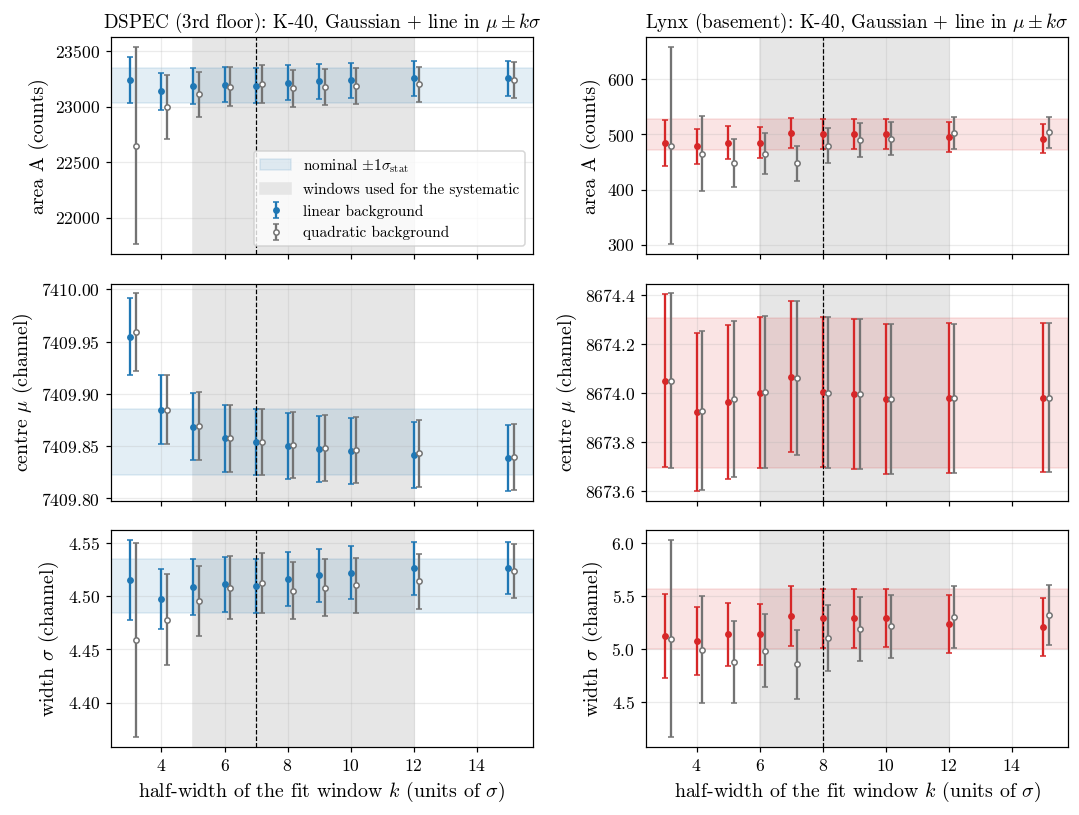

In [7]:
rows = []
for k, r in peak.items():
    sc = scan[k][(scan[k].half >= max(PLATEAU[0], HALF[k] - 2)) & (scan[k].half <= PLATEAU[1])]
    v = variations[variations.detector == k].set_index(["variation", "parameter"])
    for q, i in (("A", 0), ("mu", 1), ("sigma", 2)):
        window = 0.5 * (sc[q].max() - sc[q].min())
        background = abs(v.loc[("quadratic background", q), "shift"])
        shape = abs(v.loc[("EMG peak (tail tau)", q), "shift"])
        rows.append(dict(detector=k, parameter=q, value=r["p"][i], stat=r["err"][i], sys_window=window,
                         sys_background=background, sys_shape=shape,
                         sys_total=np.sqrt(window**2 + background**2 + shape**2)))
budget = pd.DataFrame(rows)
budget["sys_over_stat"] = budget.sys_total / budget.stat
table(budget, 4)

fig, axes = plt.subplots(3, 2, figsize=(10, 7.6), sharex=True)
for j, k in enumerate(peak):
    sc = scan[k]
    for i, (q, lab) in enumerate((("A", "area A (counts)"), ("mu", r"centre $\mu$ (channel)"), ("sigma", r"width $\sigma$ (channel)"))):
        ax = axes[i, j]
        nom = peak[k]["p"][i]
        ax.axhspan(nom - peak[k]["err"][i], nom + peak[k]["err"][i], color=COL[k], alpha=0.12, label=r"nominal $\pm1\sigma_\mathrm{stat}$")
        ax.errorbar(sc.half, sc[q], yerr=sc[f"s{q}"], fmt="o", ms=3.5, color=COL[k], capsize=2, label="linear background")
        ax.errorbar(sc.half + 0.18, sc[f"{q}_quad"], yerr=sc[f"s{q}_quad"], fmt="o", ms=3.5, mfc="white", color="0.45",
                    capsize=2, label="quadratic background")
        ax.axvspan(max(PLATEAU[0], HALF[k] - 2), PLATEAU[1], color="0.9", zorder=0, label="windows used for the systematic")
        ax.axvline(HALF[k], color="k", lw=0.8, ls="--")
        ax.set_ylabel(lab)
        ax.ticklabel_format(axis="y", useOffset=False)
        if i == 0:
            ax.set_title(f"{k}: K-40, Gaussian + line in $\\mu \\pm k\\sigma$")
    axes[2, j].set_xlabel(r"half-width of the fit window $k$ (units of $\sigma$)")
axes[0, 0].legend(fontsize=10, loc="lower right")
fig.tight_layout(); save(fig, "window_scan"); plt.show()

### What the systematic studies show
**The window.** For the DSPEC peak, linear and quadratic backgrounds agree at $\pm 7\sigma$ (shift 0.2 Barlow standard deviations), so that window is kept. For the weak Lynx peak they disagree at $\pm 7\sigma$ by 3.7 Barlow standard deviations. There the quadratic bends down at the window edges and swallows the wings of the peak, which a narrow window cannot tell apart from curvature of the background. At $\pm 8\sigma$ they agree (1.3), so $\pm 8\sigma$ is adopted. Over the defensible windows the DSPEC area stays within $\pm 34$ counts (0.15 %), its centre within $\pm 0.013$ channel and its width within $\pm 0.009$ channel, all below the statistical errors. The Lynx area stays within $\pm 9$ counts (1.7 %, a third of its statistical error). Below about $5\sigma$ the parameters drift, because the flanks are too short to fix the background.

**The background model.** A constant background is clearly wrong for the DSPEC peak ($D$ worse by 43 for one parameter fewer) and shifts the centre by 0.02 channel, which is why it is not used. Linear against quadratic changes the DSPEC area by 14 counts and the Lynx area by 21 counts in the adopted windows, both consistent with statistics by Barlow's criterion but kept as a conservative systematic.

**The peak shape.** This is the largest effect, and it differs between the two detectors only because of their statistics. On the DSPEC peak the EMG improves the deviance by 37 for one extra (fixed) shape, and the fit quality goes from $p = 0.007$ to $p = 0.74$, so the tail is real. The visible top of the peak (EMG mode) lies 0.22 channel (44 eV) above the Gaussian centre, seven times the statistical error, and the area is 0.37 % larger. On the 500-count Lynx peak the same kind of tail is invisible ($\Delta D = 0.1$), and the shift of the centre (0.12 channel) is below its statistical error.

**Total.** The DSPEC centre has a systematic error seven times its statistical one, entirely from the peak shape. Its area has a systematic error of 0.4 %, smaller than its 0.7 % statistical error. For the Lynx peak the statistical error dominates everything. This is the answer to "always suspect small errors". The tiny error on the position is real but irrelevant, because the definition of the position (Gaussian centre or top of a tailed peak) matters more. For forensics, where the area is what counts, the model choice matters at the 0.4 % level, well below the statistical error of every line except K-40 in the long DSPEC run.

## 5. Simulated peaks with a known answer

### Why
On real data we never know the true $\mu$, $\sigma$ and $A$, so we cannot tell whether the fit returns them. On simulated data we can (10:13). We generate spectra from a model with chosen parameters, add Poisson noise channel by channel (`numpy.random.Generator.poisson`, because counts are Poisson, not Gaussian), analyse each one exactly as the real data, and compare the results with the truth. Two questions are answered.

1. **Is the method unbiased and are its errors right?** Truth = the Gaussian on a line fitted above. For each simulated peak we form the pull, $(\hat p - p_\text{true})/\hat\sigma_p$. If the fit is unbiased and its errors are correct, the pulls have mean 0 and standard deviation 1. A pull width of 2 would mean the quoted errors are half the real scatter.
2. **What does the Gaussian assumption cost if the real peak has a tail?** Truth = an EMG with the tail of each detector, fitted with a Gaussian. Any average difference between the Gaussian result and the true mode or area is a bias of the method, which is exactly what a systematic error is (10:13–11:15). It is then compared with what the real data showed in Section 4.

We use 1000 simulated peaks per case, each with the same counts as the real K-40 peak of that detector.

In [8]:
rng = np.random.default_rng(SEED)
toy_rows = []
for k, r in peak.items():
    x, x0 = r["x"], r["x0"]
    lo, hi = int(x[0]), int(x[-1])
    truths = {"Gaussian truth": ("gauss", 0.0, r["p"])}
    emg_fit = fit_peak(spec[k].counts, lo, hi, r["p"][1], r["p"][2], shape="emg", tau=TAU[k])
    truths["EMG truth (tail)"] = ("emg", TAU[k], emg_fit["p"])
    truths["EMG truth, EMG fit"] = ("emg", TAU[k], emg_fit["p"])   # the tailed model refitted with itself
    for case, (shape, tau, ptrue) in truths.items():
        lam = model(ptrue, x, x0, 2, shape, tau)
        fit_emg = case == "EMG truth, EMG fit"
        gen = np.random.default_rng(SEED + 1) if fit_emg else rng
        true_pos = G.emg_mode(ptrue[1], ptrue[2], tau * ptrue[2]) if shape == "emg" and not fit_emg else ptrue[1]
        true_sig = (G.emg_fwhm(ptrue[1], ptrue[2], tau * ptrue[2]) / G.FWHM_PER_SIGMA if shape == "emg" and not fit_emg
                    else ptrue[2])
        res = []
        for _ in range(N_TOYS):
            y = np.zeros(spec[k].n)
            y[lo:hi + 1] = gen.poisson(lam)
            f = fit_peak(y, lo, hi, true_pos + gen.uniform(-0.5, 0.5), ptrue[2] * gen.uniform(0.95, 1.05),
                         shape="emg" if fit_emg else "gauss", tau=tau if fit_emg else 0.0)
            res.append((f["p"][0], f["err"][0], f["p"][1], f["err"][1], f["p"][2], f["err"][2], f["pval"]))
        res = np.array(res)
        truth_vals = (ptrue[0], true_pos, true_sig)
        for i, q in enumerate(("A", "mu", "sigma")):
            est, err = res[:, 2 * i], res[:, 2 * i + 1]
            pull = (est - truth_vals[i]) / err
            toy_rows.append(dict(detector=k, case=case, parameter=q, truth=truth_vals[i], mean_estimate=est.mean(),
                                 bias=est.mean() - truth_vals[i], bias_over_stat=(est.mean() - truth_vals[i]) / err.mean(),
                                 bias_error=est.std() / np.sqrt(N_TOYS), pull_mean=pull.mean(), pull_sd=pull.std(ddof=1),
                                 frac_p_below_0p05=np.mean(res[:, 6] < 0.05)))
toys = pd.DataFrame(toy_rows)
table(toys, 4)
for k in peak:
    t = toys[(toys.detector == k) & (toys.case == "EMG truth (tail)")].set_index("parameter")
    g = float(cal[k].gain(peak[k]["p"][1]))
    print(f"{k}: a Gaussian fitted to a tailed peak puts the centre {t.loc['mu', 'bias']:+.3f} channel "
          f"({1000 * g * t.loc['mu', 'bias']:+.0f} eV) from the true top, and the area {100 * t.loc['A', 'bias'] / t.loc['A', 'truth']:+.2f} % off")

         detector               case parameter      truth  mean_estimate     bias  bias_over_stat  bias_error  pull_mean  pull_sd  frac_p_below_0p05
DSPEC (3rd floor)     Gaussian truth         A 23189.2782     23183.6269  -5.6513         -0.0357      4.9223    -0.0386   0.9842              0.052
DSPEC (3rd floor)     Gaussian truth        mu  7409.8539      7409.8530  -0.0009         -0.0270      0.0010    -0.0271   1.0334              0.052
DSPEC (3rd floor)     Gaussian truth     sigma     4.5098         4.5083  -0.0014         -0.0561      0.0008    -0.0615   0.9880              0.052
DSPEC (3rd floor)   EMG truth (tail)         A 23275.5232     23197.0445 -78.4787         -0.4956      5.1241    -0.4989   1.0255              0.912
DSPEC (3rd floor)   EMG truth (tail)        mu  7410.0765      7409.8547  -0.2218         -6.9900      0.0010    -6.9898   1.0080              0.912
DSPEC (3rd floor)   EMG truth (tail)     sigma     4.4493         4.5116   0.0622          2.4450      0.0

### What the simulations show
**When the model is right, the method is right.** For Gaussian truths with the counts of the real K-40 peaks, the fitted area, centre and width are unbiased (all biases below 0.1 statistical error) and the pulls have standard deviations of 0.98 to 1.03. The quoted errors are therefore the real scatter, for 23 000 counts and for 500 counts alike, and about 5 % of fits have $p < 0.05$, as they should.

**When the peak has a tail, a Gaussian is biased in a predictable way.** For a DSPEC-like peak with the measured tail ($\tau = 0.49$), the Gaussian centre lies on average 0.222 channel (44 eV) below the true top of the peak, seven statistical errors, its area is 0.34 % low and its width 1.4 % high. The fits are also poor, with $p < 0.05$ in 91 % of the simulated runs. The real DSPEC data showed exactly this, a shift of 0.223 channel between the Gaussian and the EMG, 0.37 % in area and $p = 0.007$ for the Gaussian. The simulation therefore explains the real difference completely, which closes the argument. For a Lynx-like peak with 500 counts the same tail moves the centre by 0.14 channel, only 0.45 statistical errors, and the Gaussian fits are acceptable in 92 % of runs, so a weak peak cannot reveal its own tail.

The practical rule that follows is the one used in the session notebooks. Positions for the energy calibration come from the tailed model (its mode), because there the shape matters, and its tail length is measured from the strong lines of each detector. Areas are almost independent of the choice, so weak lines can be fitted with the width and tail fixed from the strong ones.

**The tailed fit passes the same test.** Refitting tailed (EMG) truths with the EMG itself gives area pulls of width 1.011 (DSPEC) and 1.013 (Lynx), and at most 1.048 for the centre and width, with 5 to 7 % of fits at $p < 0.05$. The area errors of the tailed fits used for the line table are therefore honest as well, while the Lynx centre and width errors may be understated by up to 5 %.

## 6. Calibration curves with residuals, and resolution

### Calibration (14:56)
Each detector's calibration is plotted as energy against channel, with the residuals $E_\text{fit} - E_\text{ENSDF}$ underneath. On the scale of the full curve every calibration looks perfect, because the residuals are a thousand times smaller than the energies, so only the residual plot can show whether the model (straight line or quadratic) is adequate. The error bars are the statistical position errors, and the band is the per-line systematic needed to make $\chi^2/\nu = 1$, which session 2 traced to the integral non-linearity of the ADC.

### Resolution (15:20)
The width of a line is the other property of the detector that the fit gives. For each detector the FWHM of the Gaussian part of every well-measured line is fitted with
$$ \text{FWHM}^2 = w_0^2 + w_1^2E + w_2^2E^2, $$
where $w_0$ is the electronic noise, $w_1^2E = (2.355)^2F\varepsilon E$ the statistics of the charge carriers with Fano factor $F$ and $\varepsilon = 2.96$ eV per electron–hole pair, and $w_2$ incomplete charge collection and drift. For the Lynx the empty-shield background has too few strong lines, so its IAEA-385 and Norway spectra, taken with the same detector and electronics, are pooled with it. Resolution belongs to the detector, not to the sample, so this is legitimate, provided that the system did not change between the runs. Section 16 checks this, because the Lynx ran without a gain stabiliser.

         detector  points  w0_keV   s_w0     w1   s_w1     w2  w0_core_keV  s_w0_core  fano_full    chi2  ndf   fano  s_fano  FWHM 122.06 keV  FWHM 661.657 keV  FWHM 1332.49 keV  FWHM 2614.51 keV
DSPEC (3rd floor)      13  1.2138 0.0514 0.0406 0.0025 0.0004       1.1189     0.0473     0.1006 11.7647   10 0.0855  0.0105           1.2952            1.6253            1.9950            2.6399
  Lynx (basement)      42  0.8029 0.0403 0.0406 0.0022 0.0004       0.7572     0.0380     0.1003 41.0081   39 0.0892  0.0098           0.9210            1.3458            1.7753            2.4811


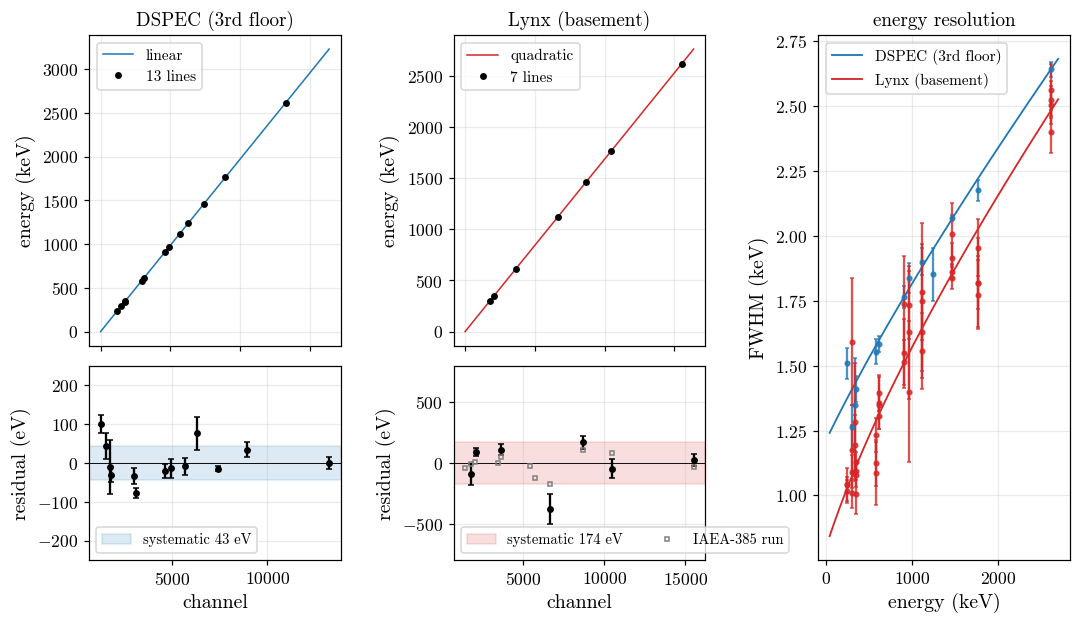

In [9]:
def resolution_points(c, k, label):
    t = c["lines"][c["lines"].used].copy()
    gain = c["cal"].gain(t.position)
    t["fwhm"] = t.fwhm_ch * gain                                   # FWHM of the whole (slightly skewed) peak
    t["sfwhm"] = t.sfwhm_ch * gain
    t["fwhm_g"] = G.FWHM_PER_SIGMA * t.sigma_ch * gain             # FWHM of its Gaussian core
    t["sfwhm_g"] = G.FWHM_PER_SIGMA * t.ssigma_ch * gain
    t["spectrum"] = label
    return t[["nuclide", "E_ref", "fwhm", "sfwhm", "fwhm_g", "sfwhm_g", "spectrum"]]


pts = {D1: resolution_points(calib[D1], D1, "background")}
lynx_pts = [resolution_points(calib[D2], D2, "background"), resolution_points(calib["IAEA-385 (Lynx)"], D2, "IAEA-385")]
for p in LYNX_OTHERS:
    s = G.read_spectrum(p)
    lynx_pts.append(resolution_points(calibrate(s, TAU[D2], calib["IAEA-385 (Lynx)"]["cal"]), D2, s.path.stem))
pts[D2] = pd.concat(lynx_pts, ignore_index=True)
RESW, RES_FULL, rows = {}, {}, []
for k, t in pts.items():
    W, Wc, chi2, ndf = G.fit_resolution(t.E_ref.values, t.fwhm.values, t.sfwhm.values)
    Wg, Wgc, _, _ = G.fit_resolution(t.E_ref.values, t.fwhm_g.values, t.sfwhm_g.values)
    fano, sfano = G.fano_from_w1(Wg[1], np.sqrt(Wgc[1, 1]))      # Fano factor from the Gaussian core
    RESW[k] = Wg
    RES_FULL[k] = W
    # Eq. (1) describes the Gaussian core (carrier statistics, noise, collection); the trapping tail is modelled by the EMG,
    # so the report quotes w0 and F from the core fit. The whole-FWHM fit (w0_keV) is kept for the FWHM curves.
    rows.append(dict(detector=k, points=len(t), w0_keV=W[0], s_w0=np.sqrt(Wc[0, 0]), w1=W[1], s_w1=np.sqrt(Wc[1, 1]), w2=W[2],
                     w0_core_keV=Wg[0], s_w0_core=np.sqrt(Wgc[0, 0]), fano_full=G.fano_from_w1(W[1])[0],
                     chi2=chi2, ndf=ndf, fano=fano, s_fano=sfano,
                     **{f"FWHM {E:g} keV": float(G.fwhm_model(E, *W)) for E in (122.06, 661.657, 1332.492, 2614.511)}))
resol = pd.DataFrame(rows)
table(resol, 4)
sigma_model = {k: (lambda E, W=W: G.fwhm_model(E, *W) / G.FWHM_PER_SIGMA) for k, W in RESW.items()}

fig = plt.figure(figsize=(11.5, 6.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.6, 1], hspace=0.08, wspace=0.45)
for j, k in enumerate((D1, D2)):
    c = calib[k]
    t = c["lines"]
    u = t[t.used]
    ax, axr = fig.add_subplot(gs[0, j]), fig.add_subplot(gs[1, j])
    xx = np.linspace(0, spec[k].n - 1, 200)
    ax.plot(xx, c["cal"].energy(xx), color=COL[k], lw=1, label="linear" if c["how"] == "linear" else "quadratic")
    ax.plot(u.position, u.E_ref, "o", ms=3.5, color="k", label=f"{len(u)} lines")
    ax.set(ylabel="energy (keV)", title=k)
    ax.tick_params(labelbottom=False)
    ax.legend(fontsize=10, loc="upper left")
    axr.axhspan(-1000 * c["cal"].sys, 1000 * c["cal"].sys, color=COL[k], alpha=0.15, label=f"systematic {1000 * c['cal'].sys:.0f} eV")
    axr.errorbar(u.position, 1000 * u.resid_keV, yerr=1000 * u.sE_stat, fmt="o", ms=3.5, color="k", capsize=2)
    axr.axhline(0, color="k", lw=0.6)
    axr.set(xlabel="channel", ylabel="residual (eV)")
    axr.legend(fontsize=9.5, loc="lower left")
    if k == D2:
        ur = calib["IAEA-385 (Lynx)"]["lines"]
        ur = ur[ur.used]
        axr.plot(ur.position, 1000 * ur.resid_keV, "s", ms=3, mfc="none", color="0.5", label="IAEA-385 run")
        axr.legend(fontsize=9.5, loc="lower left", ncol=2)
    lim = max(250, 1000 * np.max(np.abs(u.resid_keV) + u.sE_stat) * 1.6)
    axr.set_ylim(-lim, lim)
axc = fig.add_subplot(gs[:, 2])
Eg = np.linspace(40, 2700, 300)
for k, t in pts.items():
    axc.errorbar(t.E_ref, t.fwhm, yerr=t.sfwhm, fmt="o", ms=3, color=COL[k], capsize=1.5, alpha=0.8)
    W = RES_FULL[k]
    axc.plot(Eg, G.fwhm_model(Eg, *W), color=COL[k], lw=1.2, label=f"{k}")
axc.set(xlabel="energy (keV)", ylabel="FWHM (keV)", title="energy resolution")
axc.legend(fontsize=10, loc="upper left")
fig.savefig(FIG / "ir_calibration_resolution.pdf", bbox_inches="tight"); fig.savefig(FIG / "ir_calibration_resolution.png", dpi=200, bbox_inches="tight")
plt.show()

### What the calibration and resolution plots show
**Calibration.** The DSPEC scale is linear (13 lines, F-test for a quadratic term $p = 0.48$). The residuals stay within $\pm 100$ eV and need only a 43 eV per-line systematic, set by the low-energy lines that read about 0.1 keV high, as found in session 1. The Lynx scale is slightly curved. IAEA-385, with 12 strong lines, needs a quadratic term ($p_F = 4\times10^{-5}$) and shows the zigzag of the ADC's non-linearity. The empty Lynx background has only 7 usable lines, so it borrows that curvature and fits only its offset and gain, and its weak lines scatter by up to about 300 eV. In both detectors the residuals are a thousand times smaller than the energies, which is why the calibration curve itself looks perfect and only the residuals say anything.

**Resolution.** The Lynx detector resolves better at every energy, 0.92 against 1.30 keV FWHM at 122 keV and 2.48 against 2.64 keV at 2614.5 keV. Both three-term fits are good ($\chi^2/\nu = 11.8/10$ and $41.0/39$). Equation (1) is fitted to the width of each peak's Gaussian core rather than to its whole FWHM, because the equation describes only the spread from carrier statistics, electronic noise and charge collection, while the low-energy tail from charge trapping is a separate effect that the EMG already models. The whole FWHM is 8.5 % (DSPEC) and 6.0 % (Lynx) wider than the core, and because the tail length is a fixed multiple of the width, a fit to the whole FWHM scales every term up together. It gives $w_0$ = 1.21 against 0.80 keV and Fano factors of about 0.10 for both detectors, which reads part of the tail as noise and carrier spread. Fitted to the cores, the noise term is $w_0 = 1.12 \pm 0.05$ against $0.76 \pm 0.04$ keV, and this difference comes from the electronics and the detector capacitance. The carrier-statistics term is the same in both and gives Fano factors of $0.086 \pm 0.010$ and $0.089 \pm 0.010$, consistent with the value of about 0.1 usually quoted for germanium. At high energy the two converge because carrier statistics and charge collection dominate there, and these are properties of germanium rather than of a particular system.

## 7. Every line in both backgrounds: rates and widths

### What we compare, and why (14:08, 16:02)
Once a peak is identified, its centre has done its job and the area is what matters, because the area divided by the live time is the rate at which that nuclide's γ rays reach the crystal. The table therefore lists, for each line, the rate in counts per day in each background (counts per second would give awkward numbers of order $10^{-3}$), its statistical error, and the ratio of the two detectors. The width is listed too where the line is strong enough to measure it.

### Method
Each line is fitted at the energy where the calibration puts it, in both spectra, whether or not a search found it there, so the two detectors are measured identically. The width is fixed from each detector's own resolution model and the tail from its own $\tau$, which keeps weak fits stable (only the area, the position and a straight background are free). Lines that are too close to resolve are fitted together (Pb-212 at 238.6 with Pb-214 at 242.0 keV, Pb-214 at 295.2 with Pb-212 at 300.1 keV). The 511 keV annihilation line is fitted with a free width, because the motion of the electrons that annihilate broadens it beyond the detector resolution. The FWHM column comes from a separate fit with the width free, for lines above 10 standard deviations. Each fit's deviance and $p$-value are kept as well, because a rate without a goodness of fit cannot be judged. Fixing the width has a price for a line whose width in a particular run differs from the curve, which Section 14 measures for K-40. The Cs-137 line in the third-floor background is examined in Section 15, and Section 19 predicts every line's error before fitting.

### What the ratio means, and what it does not
A rate is the product of the photon flux at the crystal and the detector's full-energy efficiency. The two detectors differ in crystal size (unknown to us), in shielding and in location, so the ratio mixes all of these. A ratio that is the same for all lines would point to efficiency alone. Ratios that differ between lines tell us about the sources, because each kind of source (rock and concrete outside the shield, radon inside it, contamination of the detector, cosmic rays) responds to shielding and location in its own way.

In [10]:
NONPOS = []   # channels where a fitted line model fell to zero or below
LINES = [("Pb-210", 46.539, []), ("Pb K-alpha1 X-ray", 74.969, [72.805]), ("U-235 + Ra-226", 186.0, []),
         ("Pb-212", 238.632, [241.995]), ("Pb-214", 295.224, [300.087]), ("Pb-214", 351.932, []), ("annihilation", 510.999, []),
         ("Tl-208", 583.187, []), ("Bi-214", 609.321, []), ("Cs-137", 661.657, []), ("Pb-206(n,n')", 803.1, []),
         ("Ac-228", 911.204, []), ("Bi-214", 1120.294, []), ("K-40", 1460.820, []), ("Bi-214", 1764.491, []),
         ("Tl-208", 2614.511, [])]
rows = []
for name, E, nb in LINES:
    r = {"line": f"{name} {E:.1f}", "E": E}
    for k in (D1, D2):
        free = name == "annihilation"
        p, fit = G.fit_line_at(spec[k], cal[k], E, sigma_model[k], TAU[k], free_width=free, neighbours=nb)
        NONPOS.append(p["n_nonpositive"])
        tag = "1" if k == D1 else "2"
        r[f"cpd{tag}"], r[f"s_cpd{tag}"] = 86400 * p["rate"], 86400 * p["s_rate"]
        r[f"z{tag}"] = p["rate"] / p["s_rate"]
        r[f"D{tag}"], r[f"ndf{tag}"], r[f"p{tag}"] = p["dev"], p["ndf"], p["pval"]          # goodness of fit of this line fit
        if r[f"z{tag}"] > 10 or free:
            pw, _ = G.fit_line_at(spec[k], cal[k], E, sigma_model[k], TAU[k], free_width=True, neighbours=nb)
            g = float(cal[k].gain(cal[k].channel(E)))
            r[f"fwhm{tag}"], r[f"s_fwhm{tag}"] = pw["fwhm"] * g, pw["sfwhm"] * g
        else:
            r[f"fwhm{tag}"], r[f"s_fwhm{tag}"] = np.nan, np.nan
    if r["z1"] > 3 and r["z2"] > 3:
        r["ratio_1_over_2"], r["s_ratio"] = G.ratio(r["cpd1"], r["s_cpd1"], r["cpd2"], r["s_cpd2"])
    else:
        r["ratio_1_over_2"], r["s_ratio"] = np.nan, np.nan
    rows.append(r)
lines_tab = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.3g}".format):
    print(lines_tab.drop(columns="E").to_string(index=False))

BANDS = [(40, 100), (100, 200), (200, 500), (500, 1000), (1000, 1450), (1500, 2600), (2650, 2750)]
rows = []
for lo, hi in BANDS:
    v1, s1 = G.window_rate(spec[D1], cal[D1], lo, hi)
    v2, s2 = G.window_rate(spec[D2], cal[D2], lo, hi)
    rows.append(dict(band=f"{lo}-{hi}", cpd_per_keV_1=86400 * v1, s1=86400 * s1, cpd_per_keV_2=86400 * v2, s2=86400 * s2,
                     ratio_1_over_2=v1 / v2, s_ratio=(v1 / v2) * np.hypot(s1 / v1, s2 / v2)))
bands = pd.DataFrame(rows)
print()
table(bands, 3)
for k in (D1, D2):
    s = spec[k]
    i0 = int(np.ceil(cal[k].channel(40)))
    i1 = int(np.floor(cal[k].channel(2700)))
    print(f"{k}: total rate 40-2700 keV = {s.counts[i0:i1 + 1].sum() / s.live:.3f} counts per second, "
          f"all recorded channels = {s.counts.sum() / s.live:.3f} counts per second")
r_band = [spec[k].counts[int(np.ceil(cal[k].channel(40))):int(np.floor(cal[k].channel(2700))) + 1].sum() / spec[k].live
          for k in (D1, D2)]
print(f"third floor over basement: {r_band[0] / r_band[1]:.2f} between 40 and 2700 keV, "
      f"{(spec[D1].counts.sum() / spec[D1].live) / (spec[D2].counts.sum() / spec[D2].live):.2f} over all recorded channels")
print(f"line fits whose model fell to zero or below in some channel: {sum(n > 0 for n in NONPOS)} of {len(NONPOS)}")

                  line     cpd1  s_cpd1   z1   D1  ndf1       p1  fwhm1  s_fwhm1     cpd2  s_cpd2   z2   D2  ndf2     p2  fwhm2  s_fwhm2  ratio_1_over_2  s_ratio
           Pb-210 46.5      605    28.1 21.5 33.5    33    0.443   1.21   0.0732     21.1    12.2 1.72 27.6    26  0.376    NaN      NaN             NaN      NaN
Pb K-alpha1 X-ray 75.0 9.16e+03    61.5  149 90.3    42 2.18e-05   1.27  0.00745      200      15 13.3 45.3    38  0.194  0.653   0.0573            45.7     3.44
  U-235 + Ra-226 186.0      634    28.7 22.1 29.3    35    0.739   1.35   0.0792     16.6    15.6 1.06 27.7    31  0.634    NaN      NaN             NaN      NaN
          Pb-212 238.6      878    27.7 31.7 57.2    51    0.255   1.46   0.0556     45.1    14.7 3.06   49    50  0.512    NaN      NaN            19.5     6.38
          Pb-214 295.2      428    22.6   19 83.6    60   0.0236   1.24   0.0847      120    14.1 8.53 62.2    61  0.432    NaN      NaN            3.56    0.458
          Pb-214 351.9      

### Which background is higher, and why (18:12)
**The third-floor DSPEC background is higher, at every energy and in every line.** Its total rate between 40 and 2700 keV is 5.93 counts per second against 1.56 in the basement. Line by line, however, the ratio ranges from 2.7 to 46, and that range is what explains it.

* **Environmental γ rays from outside the shield** (K-40 38 times, Pb-212 20 times, and Tl-208 at 583 keV and Ac-228 at 911 keV, not even detected in the basement) fall most. The Tl-208 line at 2614.5 keV falls by only 7.4, although it comes from the same decays as the 583 keV line, and lead attenuates 583 keV photons much more strongly than 2614.5 keV ones. So the basement detector is behind much more lead, which hardens the spectrum that gets through. A larger crystal on the third floor could not do this, because efficiency changes smoothly with energy and would scale all lines similarly.
* **Lead X-rays and Pb-210** (46 times, and Pb-210 at 46.5 keV not detected in the basement) come from the shield itself, from muons and photons exciting lead atoms and from Pb-210 in old lead. A copper or cadmium liner, or newer lead, removes them.
* **Radon daughters** (Pb-214 at 352 keV only 3.8 times lower, Bi-214 9 to 17 times) fall least among the γ lines, because radon gets into the air inside the shield, where no lead stands between it and the crystal. In the basement, close to the ground, radon is the main source of lines.
* **Cosmic rays** fall least of all. The 511 keV annihilation line is 2.7 times lower and the continuum above 2650 keV, which only cosmic-ray events reach, 1.7 times. Muons pass through lead, so shielding cannot remove them, and only the overburden of several floors above the basement reduces them. The 803 keV line of Pb-206, excited by neutrons that muons produce in the lead, is the one feature not lower in the basement (32 counts per day in both), consistent with more lead around the basement detector.

The continuum ratio follows the same pattern, highest at 40–100 keV (6.6, the X-ray region and low-energy photons that lead absorbs best) and lowest above 2650 keV (1.7, cosmic rays). So the basement detector is lower because it is better shielded and deeper, and what remains is radon inside the shield and cosmic rays, which is where its background could still be improved (nitrogen flushing, a muon veto).

**Resolution in the background lines.** Where both detectors measure a line well enough to fit its width, the widths are close to each detector's resolution model, for example 2.07 against 2.03 keV for K-40 and 2.65 against 2.60 keV for Tl-208 at 2614.5 keV, while at low energy the Lynx is clearly sharper (Pb-214 at 352 keV, 1.39 against 1.02 keV). The 511 keV line is 2.55 keV wide in both, far wider than the 1.2 to 1.5 keV of a photopeak at that energy, because the electrons that annihilate are moving and Doppler-shift the photons.

## 8. Showing the two spectra so that the comparison is clear

### The problem (13:00–14:08)
A spectrum has 16 384 channels over almost 3 MeV, and the lines are a few channels wide, so a whole spectrum on one page shows the overall level but hides the lines. The two detectors also have different channel widths (0.197 against 0.168 keV) and different live times, so raw counts per channel cannot be compared at all.

### What we do
* Both spectra are converted to **counts per keV per day**. Each channel's counts are shared out between fixed energy bins in proportion to their overlap (so counts are conserved), then divided by the bin width and the live time. This is the correction for different binning that the demonstrator asked for.
* The top panel shows the whole range in 10 keV bins on a logarithmic scale, which shows the continuum, with the ratio of the two underneath.
* The lower panels zoom into the regions that carry the argument, in 0.5 keV bins on a logarithmic scale, namely the lead X-rays and Pb-210, the Pb-212 and Pb-214 lines, the 583/609/662 keV group, K-40 and Tl-208 at 2614.5 keV. The same y-scale is used for both detectors in each panel, so heights compare directly.

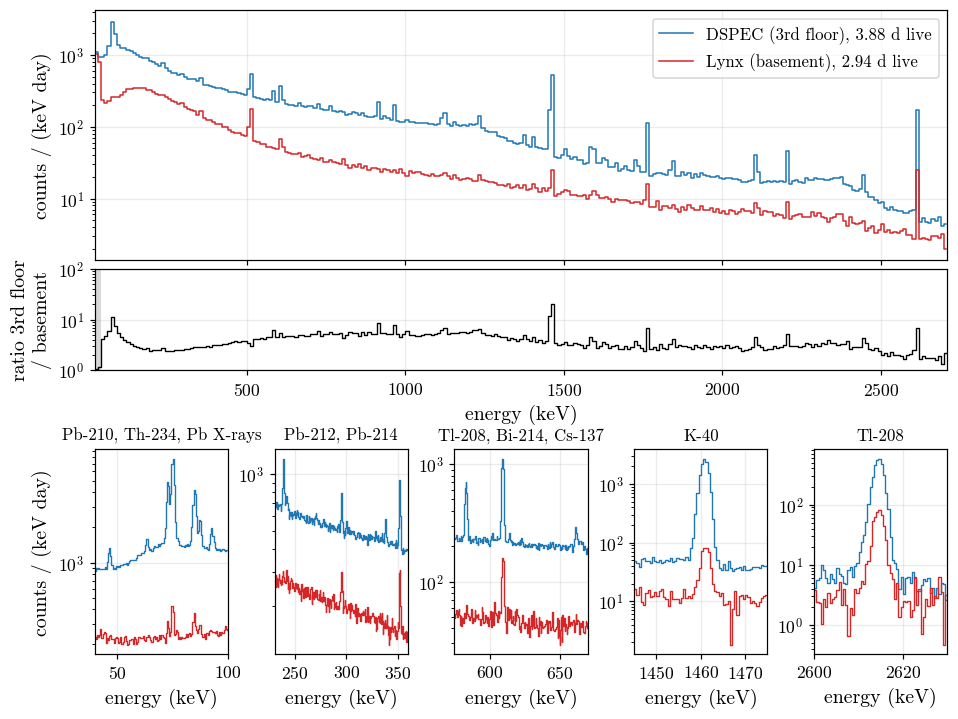

In [11]:
from matplotlib.ticker import NullFormatter
fig = plt.figure(figsize=(10, 7.6))
outer = fig.add_gridspec(2, 1, height_ratios=[2.2, 1.25], hspace=0.28)
top = outer[0].subgridspec(2, 1, height_ratios=[1.6, 0.65], hspace=0.05)
bottom = outer[1].subgridspec(1, 5, wspace=0.35)
ax = fig.add_subplot(top[0])
axr = fig.add_subplot(top[1], sharex=ax)
edges = np.arange(20, 2711, 10.0)
cen = 0.5 * (edges[1:] + edges[:-1])
rates = {}
for k in (D1, D2):
    r_, s_ = G.rebin_to_energy(spec[k], cal[k], edges)
    rates[k] = (86400 * r_, 86400 * s_)
    ax.step(cen, rates[k][0], where="mid", color=COL[k], lw=1, label=f"{k}, {spec[k].live / 86400:.2f} d live")
ax.set(yscale="log", ylabel="counts / (keV day)", xlim=(20, 2710))
ax.tick_params(labelbottom=False)
ax.legend(fontsize=11)
q = rates[D1][0] / rates[D2][0]
axr.step(cen, q, where="mid", color="k", lw=0.9)
axr.set(yscale="log", ylabel=f"ratio 3rd floor\n/ basement", xlabel="energy (keV)", ylim=(1, 100))
axr.axvspan(20, 40, color="0.85", lw=0)
zooms = [(40, 100, "Pb-210, Th-234, Pb X-rays"), (230, 360, "Pb-212, Pb-214"), (575, 670, "Tl-208, Bi-214, Cs-137"),
         (1445, 1475, "K-40"), (2600, 2630, "Tl-208")]
for j, (lo, hi, title) in enumerate(zooms):
    a = fig.add_subplot(bottom[j])
    e = np.arange(lo, hi + 0.01, 0.5)
    c = 0.5 * (e[1:] + e[:-1])
    for k in (D1, D2):
        r_, _ = G.rebin_to_energy(spec[k], cal[k], e)
        a.step(c, 86400 * r_, where="mid", color=COL[k], lw=0.9)
    a.set(title=title, xlabel="energy (keV)", xlim=(lo, hi), yscale="log")
    a.yaxis.set_minor_formatter(NullFormatter())
    a.title.set_fontsize(11)
    if j == 0:
        a.set_ylabel("counts / (keV day)")
fig.savefig(FIG / "ir_backgrounds.pdf", bbox_inches="tight"); fig.savefig(FIG / "ir_backgrounds.png", dpi=200, bbox_inches="tight")
plt.show()

### Reading the figure
The top panel shows that the DSPEC spectrum lies above the Lynx spectrum over the whole range, by a factor that changes smoothly from about 7 near 60 keV to under 2 above 2.6 MeV (ratio panel), with spikes at the lines that the basement shield removes most (lead X-rays, K-40, Tl-208 at 583 keV, Ac-228). Below 40 keV the Lynx spectrum has the sharp step found in session 2 and is not used. The zoom panels show the same thing line by line. The Pb X-rays and Pb-210 dominate the low-energy DSPEC spectrum and are faint or absent in the Lynx, the two radon lines at 295 and 352 keV stand out almost as clearly in both, the Tl-208/Bi-214/Cs-137 group nearly vanishes in the basement except for the radon line at 609 keV, and K-40 and Tl-208 at 2614.5 keV show the different suppression of an external line at medium and at high energy. The narrower peaks of the Lynx detector are visible directly in every panel.

## 9. The K-40 fits as they will appear in the report

The demonstrator's minimum for any fit (20:25) is the fitted value, the statistical error, the systematic error with its source, and the goodness of fit, in a plot or a table next to it, with sensible significant figures. Errors are rounded by the Particle Data Group rule (two significant figures if their leading digits are 100 to 354, otherwise one) and values to the same decimal place, as in the report's tables. The figure shows the data with Poisson error bars, the fitted Gaussian and its straight background, and the normalised residuals $(n_i - f_i)/\sqrt{f_i}$ underneath, which should scatter as standard normal numbers if the model is right. The EMG fit is overlaid as a dashed line, so that the tail is visible where the Gaussian residuals show it.

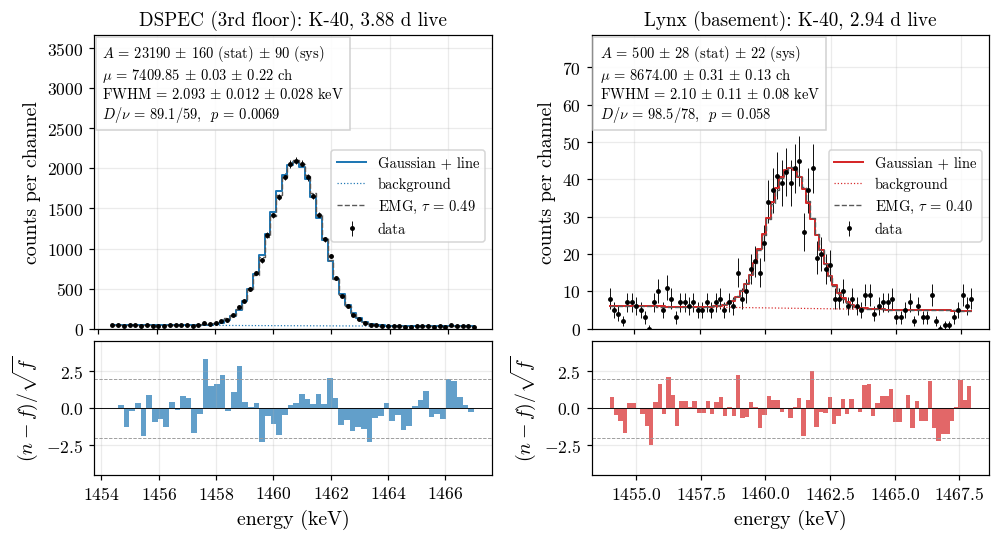

In [12]:
def pdg(value, *errs):
    # round errors by the Particle Data Group rule (two figures if the leading digits are 100 to 354, else one)
    # and the value to the same decimal place; the same rule makes the report's tables
    e = max(errs)
    exponent = int(np.floor(np.log10(e)))
    d = (1 - exponent) if int(e / 10**(exponent - 2)) <= 354 else -exponent
    r = lambda x: f"{round(x, d):.{max(d, 0)}f}" if d > 0 else f"{int(round(x, d))}"
    return [r(value)] + [r(x) for x in errs]


fig = plt.figure(figsize=(10.5, 5.2))
gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1], hspace=0.06, wspace=0.25)
for j, (k, r) in enumerate(peak.items()):
    ax, axr = fig.add_subplot(gs[0, j]), fig.add_subplot(gs[1, j])
    E = cal[k].energy(r["x"])
    ax.errorbar(E, r["y"], yerr=np.sqrt(np.maximum(r["y"], 1)), fmt="o", ms=2.2, color="k", elinewidth=0.6, label="data")
    ax.step(E, r["f"], where="mid", color=COL[k], lw=1.3, label="Gaussian + line")
    bk = model(np.r_[0.0, r["p"][1:]], r["x"], r["x0"], 2, "gauss", 0.0)
    ax.plot(E, bk, color=COL[k], lw=0.8, ls=":", label="background")
    emg = fit_peak(spec[k].counts, int(r["x"][0]), int(r["x"][-1]), r["p"][1], r["p"][2], shape="emg", tau=TAU[k])
    ax.step(E, emg["f"], where="mid", color="0.35", lw=0.9, ls="--", label=fr"EMG, $\tau$ = {TAU[k]:.2f}")
    row = k40[k40.detector == k].iloc[0]
    bud = budget[budget.detector == k].set_index("parameter")
    gain = row.FWHM_keV / (G.FWHM_PER_SIGMA * row.sigma)
    A_ = pdg(row.A, row.sA, bud.loc["A", "sys_total"])
    mu_ = pdg(row.mu, row.smu, bud.loc["mu", "sys_total"])
    fw_ = pdg(row.FWHM_keV, row.sFWHM_keV, G.FWHM_PER_SIGMA * gain * bud.loc["sigma", "sys_total"])
    txt = (f"$A$ = {A_[0]} $\\pm$ {A_[1]} (stat) $\\pm$ {A_[2]} (sys)\n"
           f"$\\mu$ = {mu_[0]} $\\pm$ {mu_[1]} $\\pm$ {mu_[2]} ch\n"
           f"FWHM = {fw_[0]} $\\pm$ {fw_[1]} $\\pm$ {fw_[2]} keV\n"
           f"$D/\\nu$ = {row.D:.1f}/{int(row.ndf)},  $p$ = {row.p_value:.2g}")
    ax.text(0.02, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9.5, bbox=dict(fc="white", ec="0.8", alpha=0.9))
    ax.set(title=f"{k}: K-40, {spec[k].live / 86400:.2f} d live", ylabel="counts per channel", ylim=(0, 1.75 * r["y"].max()))
    ax.tick_params(labelbottom=False)
    ax.legend(fontsize=9.5, loc="center right", bbox_to_anchor=(1.0, 0.45))
    axr.bar(E, (r["y"] - r["f"]) / np.sqrt(r["f"]), width=float(cal[k].gain(r["p"][1])), color=COL[k], alpha=0.7)
    axr.axhline(0, color="k", lw=0.6)
    for yv in (-2, 2):
        axr.axhline(yv, color="0.6", lw=0.6, ls="--")
    axr.set(xlabel="energy (keV)", ylabel=r"$(n-f)/\sqrt{f}$", ylim=(-4.5, 4.5))
fig.savefig(FIG / "ir_k40_fits.pdf", bbox_inches="tight"); fig.savefig(FIG / "ir_k40_fits.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Two days against four (summary of notebook 2)

The Norway 2 sediment was counted on the Lynx for 3.97 days in session 2 and again for 1.96 days in session 3. The full analysis is in `notebooks/2_counting_time.ipynb`. For the report one figure carries the argument. Its left panel shows by how much each line's error grew in the shorter run, against the $\sqrt{t_\text{old}/t_\text{new}} = 1.43$ that counting statistics predict, for gross rates and for background-subtracted net rates. The right panel shows how the uncertainty of the Cs-137/K-40 activity ratio would fall with longer counting, split into the part that scales with the sample's counting time and the part fixed by the background run, the IAEA-385 run and the certificate. It is rebuilt from the saved session-3 tables, so nothing is recomputed here.

### How we know that the short run is Norway 2, and what the counts did
The file of the two-day run is named only "Tuesday test run", so the sample was identified from the data (session 3, Section A5). The gross rates of seven lines that belong to the sample (K-40, Cs-137, and the thorium chain) were compared with each of the two session-2 sediments. They agree with Norway 2 ($\chi^2 = 8.2$ for 7 lines, $p = 0.31$) and not with Norway 1 ($\chi^2 = 40.1$, $p = 1.2\times10^{-6}$). The decisive line is Cs-137, at 152 counts per day against 164 in Norway 2 and 243 in Norway 1. The K-40 and Pb-212 rates also match Norway 2 in absolute terms, so it was the same pot in the same position.

The four-day run holds 785 110 counts in total and the two-day run 380 802, a ratio of 0.485 for a live-time ratio of 0.492. With more than a million counts this fall of the total rate, $1.45 \pm 0.19$ %, is far beyond statistics (a binomial test conditioned on the total gives $p = 1.4\times10^{-13}$). It comes together with the change of the radon lines and of the 200 to 500 keV continuum, which is consistent with less radon in the shield during the second run. The sample lines themselves agree, hence for them what changes is only how well the rates are known, since $N$ counts carry a relative error of $1/\sqrt N$. The other group's run is often called "five days", but its live time was 3.97 days.

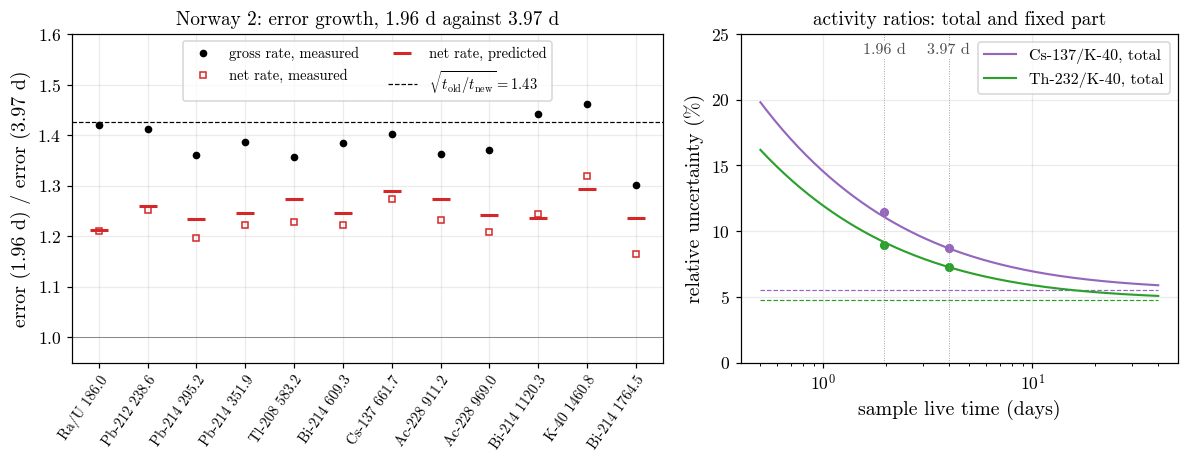

simulated spread ratio 2 d / 4 d over 19 lines: 1.422 (prediction 1.425)
mean gross-error ratio 1.388, mean net-error ratio 1.231 (predicted 1.254) over 12 detected lines


In [13]:
prec = pd.read_csv(S3_RESULTS / "s3_precision.csv")
bud3 = pd.read_csv(S3_RESULTS / "s3_uncertainty_budget.csv")
simsum = pd.read_csv(S3_RESULTS / "s3_simulation_lines.csv")
T_OLD, T_NEW = 3.9740, 1.9558
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
det = prec[prec.z_old > 3].reset_index(drop=True)
x = np.arange(len(det))
ax.plot(x, det.gross_err_ratio, "o", color="k", ms=4, label="gross rate, measured")
ax.plot(x, det.net_err_ratio, "s", color="tab:red", mfc="none", ms=4.5, label="net rate, measured")
ax.plot(x, det.net_err_ratio_pred, "_", color="tab:red", ms=12, mew=2, label="net rate, predicted")
ax.axhline(np.sqrt(T_OLD / T_NEW), color="k", ls="--", lw=0.8, label=r"$\sqrt{t_\mathrm{old}/t_\mathrm{new}}=1.43$")
ax.axhline(1, color="0.5", lw=0.6)
ax.set(xticks=x, ylabel="error (1.96 d) / error (3.97 d)", ylim=(0.95, 1.6),
       title="Norway 2: error growth, 1.96 d against 3.97 d")
ax.set_xticklabels([l.replace("Ra-226 + U-235", "Ra/U") for l in det.line], fontsize=9.5, rotation=55, ha="right", rotation_mode="anchor")
ax.legend(fontsize=9.5, ncol=2, loc="upper center")
ax = axes[1]
tt = np.geomspace(0.5, 40, 200)
for ratio_name, col in (("Cs-137/K-40 (Cs-137)", "tab:purple"), ("Th-232/K-40 (Pb-212)", "tab:green")):
    old = bud3[(bud3.ratio == ratio_name) & (bud3.run == "Norway 2")].iloc[0]
    new = bud3[(bud3.ratio == ratio_name) & (bud3.run == "session 3")].iloc[0]
    v = old["rel error (%)"]**2
    vs = v * old["sample share of variance (%)"] / 100
    ax.plot(tt, np.sqrt(vs * T_OLD / tt + (v - vs)), color=col, lw=1.4, label=ratio_name.split(" (")[0] + ", total")
    ax.plot(tt, np.sqrt(v - vs) * np.ones_like(tt), color=col, lw=0.8, ls="--")
    ax.plot([T_OLD, T_NEW], [old["rel error (%)"], new["rel error (%)"]], "o", color=col, ms=5)
for T, lab in ((T_NEW, "1.96 d"), (T_OLD, "3.97 d")):
    ax.axvline(T, color="0.6", lw=0.6, ls=":")
    ax.text(T, 23.5, lab, fontsize=10.5, ha="center", color="0.3", bbox=dict(fc="white", ec="none", pad=0.5))
ax.set(xscale="log", xlabel="sample live time (days)", ylabel="relative uncertainty (%)", ylim=(0, 25),
       title="activity ratios: total and fixed part")
ax.legend(fontsize=10.5)
fig.tight_layout()
fig.savefig(FIG / "ir_two_vs_four_days.pdf", bbox_inches="tight"); fig.savefig(FIG / "ir_two_vs_four_days.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"simulated spread ratio 2 d / 4 d over 19 lines: {simsum['sd ratio 2d/4d'].mean():.3f} (prediction {np.sqrt(T_OLD / T_NEW):.3f})")
print(f"mean gross-error ratio {det.gross_err_ratio.mean():.3f}, mean net-error ratio {det.net_err_ratio.mean():.3f} "
      f"(predicted {det.net_err_ratio_pred.mean():.3f}) over {len(det)} detected lines")

# Part 2. Further questions for the report

A check of the analysis against the demonstrator's recordings, the lab script and our own notes (13 November 2026) found points that were either stated without a reason or missing. Each gets a short section here, with the same structure as before (why, the physics, the method, what the result means), so that every sentence added to the report has a number behind it.

| Question | Section |
|---|---|
| What do the `.Chn` and `.csv` files contain, what is a bin, and how do two different bin widths become comparable? | 11 |
| Why does the K-40 peak look tilted, on a linear and on a logarithmic axis? | 12 |
| Is our fit the same as InterSpec's, why not, and which is better? | 13 |
| Why do Table 1 and Table 2 of the report give two different K-40 rates? | 14 |
| There is Cs-137 in the third-floor background. Does it matter? | 15 |
| Is the Lynx stable from run to run without a gain stabiliser, and is the K-40 width change real? | 16 |
| Numbers for the plans: radon ingrowth after sealing, how to divide counting time, self-absorption | 17 |
| Extension from the lab script: a first limit on neutrinoless double beta decay | 18 |
| Which line will have the worst uncertainty? Predicting errors before fitting, and pulls | 19 |

All fits use the raw counts on a linear scale. Logarithmic axes appear only in plots, as the demonstrator asked on 13 October (keep the mathematics in linear space and use a logarithmic scale only to look at the spectrum).

## 11. From the files to a comparable spectrum: channels, bins and bin width

### Why
The two detectors hand us two different files, a binary ORTEC `.Chn` from Maestro and a text `.csv` from the Lynx web page. Before anything is fitted we have to know what each file contains, what one "bin" means in each, and why the same physics gives different numbers of counts per bin in the two. The demonstrator's last remark on 3 November was exactly this ("they've got different binning, so your y-axis needs to be counts per bin, effectively", 30:37).

### What a channel is
The MCA measures the height of every pulse and sorts it into one of 16 384 equal intervals of pulse height, the channels. A spectrum file is the list of how many pulses fell into each channel. A channel is therefore a bin of pulse height, not of energy. The energy width of a bin is the gain of the whole chain (preamplifier, digital filter, coarse and fine gain) and is fixed only when a calibration $E(n)$ is known,
$$ \Delta E_\text{bin} = \frac{\mathrm{d}E}{\mathrm{d}n}. $$
Both MCAs spread 16 384 channels over their full range, but the gains differ. The DSPEC covers about 3230 keV, so each bin is 0.197 keV wide, and the Lynx covers about 2760 keV, so each bin is 0.168 keV wide. A flat continuum of $r$ counts per keV per day puts $r\,\Delta E_\text{bin}\,t$ counts into each bin, so the Lynx would show 15 % fewer counts per bin than the DSPEC for the same physics and the same counting time.

### What each file stores

| | ORTEC `.Chn` (DSPEC-LF, Maestro) | Lynx `.csv` (web interface) |
|---|---|---|
| Form | binary: 32-byte header, one 4-byte integer per channel, then a trailer | text: a few header lines, then one row per channel |
| Channel numbering | starts at 0 | starts at 1 |
| Times | real and live time in ticks of 20 ms, start date and time | real and live time in seconds, start time as a text stamp |
| Calibration | three coefficients in the trailer, here stale (3.3 keV low at 2614.5 keV) | "Offset 0, Slope 1", so the "Energy (keV)" column is only the channel number |
| Acquisition settings | none | none (which is why we photographed the Lynx settings) |

Maestro can also print the spectrum as a `.txt` file, which holds the counts but no times, so it cannot give rates by itself. The cell below checks that the `.txt` and the `.Chn` hold identical counts. Our reader turns both formats into the same object (counts, live time, real time, start), and the calibration is always our own.

### From counts per bin to counts per keV per day
Three steps make two spectra comparable. Dividing by the live time removes the different counting times. Dividing by the bin width in keV removes the different gains. For plots, the counts are then moved onto a common energy grid, each channel's counts being shared between the new bins in proportion to the overlap, which conserves the total. Fits never use rebinned data, because rebinning correlates neighbouring bins and the Poisson likelihood assumes independent counts.

### What goes wrong without it
Comparing raw counts per channel would mix three things that have nothing to do with the sources (live time, bin width, and the fact that a given energy sits at a different channel number in each detector).

In [14]:
rows = []
for k, s in spec.items():
    gain = lambda E: float(cal[k].gain(cal[k].channel(E)))
    rows.append({"detector": k, "file": s.path.name, "format": s.fmt, "channels": s.n,
                 "first channel label": s.meta["first_channel_label"], "live time (d)": round(s.live / 86400, 4),
                 "real time (d)": round(s.real / 86400, 4), "dead time (%)": round(100 * s.dead_fraction, 3),
                 "calibration stored in file": str(tuple(round(v, 5) for v in s.stored_cal)),
                 "bin width at 100 keV (keV)": round(gain(100.0), 5), "bin width at 1460.8 keV (keV)": round(gain(K40), 5),
                 "bin width at 2614.5 keV (keV)": round(gain(2614.511), 5),
                 "full range (keV)": round(float(cal[k].energy(s.n - 1)), 0)})
formats = pd.DataFrame(rows).set_index("detector").T
print(formats.to_string())

txt_counts = G.read_maestro_txt(ROOT / "data" / "raw" / "BkgRun5_Long_txt.Txt")
print(f"\nMaestro .txt printout holds the same counts as the .Chn file: {np.array_equal(txt_counts, spec[D1].counts)}")

# the same stretch of continuum (1800 to 2000 keV) in three normalisations
rows = []
for k in (D1, D2):
    i0, i1 = int(np.ceil(cal[k].channel(1800))), int(np.floor(cal[k].channel(2000)))
    N, n_ch = spec[k].counts[i0:i1 + 1].sum(), i1 - i0 + 1
    rows.append({"detector": k, "channels in 1800-2000 keV": n_ch, "counts per channel": N / n_ch,
                 "counts per channel per day": N / n_ch / (spec[k].live / 86400),
                 "counts per keV per day": 86400 * G.window_rate(spec[k], cal[k], 1800, 2000)[0]})
norm = pd.DataFrame(rows).set_index("detector").astype(float)
norm.loc["ratio 3rd floor / basement"] = norm.loc[D1] / norm.loc[D2]
print()
print(norm.round(3).to_string())

edges10 = np.arange(20, 2711, 10.0)
for k in (D1, D2):
    r_, _ = G.rebin_to_energy(spec[k], cal[k], edges10)
    c0, c1 = float(cal[k].channel(20.0)), float(cal[k].channel(2710.0))
    direct = np.interp([c0, c1], np.arange(spec[k].n + 1) - 0.5, np.r_[0.0, np.cumsum(spec[k].counts)])
    print(f"{k}: counts between 20 and 2710 keV, rebinned {np.sum(r_ * spec[k].live * 10.0):.1f}, in the raw channels {direct[1] - direct[0]:.1f}")

detector                             DSPEC (3rd floor)               Lynx (basement)
file                                  BkgRun5_Long.Chn  backround_run_hpge_12_10.csv
format                                       ortec-chn                      lynx-csv
channels                                         16384                         16384
first channel label                                  0                             1
live time (d)                                   3.8826                        2.9363
real time (d)                                   3.8872                        2.9369
dead time (%)                                    0.118                         0.019
calibration stored in file     (0.67636, 0.19664, 0.0)               (0.0, 1.0, 0.0)
bin width at 100 keV (keV)                      0.1971                       0.16837
bin width at 1460.8 keV (keV)                   0.1971                       0.16847
bin width at 2614.5 keV (keV)                   0.1971           

### What the files and the bin widths show
Both files hold 16 384 channels, but nothing else about them is the same. The `.Chn` file numbers its channels from 0 and carries a calibration that is out of date, and the `.csv` file numbers them from 1 and carries none. Neither stores the acquisition settings. The dead time is 0.12 % for the DSPEC and 0.02 % for the Lynx, so live and real time differ very little here, but all rates use the live time because that is the time during which a pulse could be recorded. The Maestro `.txt` printout holds exactly the same counts as the `.Chn` file.

The bin width is 0.1971 keV for the DSPEC, constant over the spectrum because its scale is linear, and 0.1684 keV for the Lynx at 100 keV, rising to 0.1686 keV at 2614.5 keV because its scale is slightly curved. The ratio is 1.17. The same 16 384 channels therefore cover 3229 keV in one detector and 2760 keV in the other, and the stretch from 1800 to 2000 keV occupies 1015 DSPEC channels but 1187 Lynx channels.

The three normalisations of that stretch show why the correction is needed. In raw counts per channel the third-floor spectrum is 4.67 times higher than the basement one. Dividing by the live time brings this to 3.53, and dividing by the bin width as well to 3.02. The raw comparison would therefore overstate the difference between the two rooms by 55 %, of which 32 % is the longer DSPEC run and 17 % its wider bins. The value of 3.02 counts per keV per day is the only one of the three that describes the radiation and not the settings.

Sharing each channel's counts between the 10 keV bins of the plots conserves the total exactly (the two sums printed above agree), so the figure in Section 8 shows the same counts as the raw files, only on a common energy axis.

## 12. Why the K-40 peak looks tilted

### Why
A pure Gaussian on a flat floor is symmetric. The measured K-40 peak is not. Its floor is higher on the left than on the right, and its left side is fuller than its right side, on a linear axis and on a logarithmic one. The demonstrator raised it as a source of systematic error ("what if the shape is slightly distorted by a background, or there's a tail on one side", 04:55), and we should be able to say where the tilt comes from before choosing a model. There are four possible causes, and each leaves a different mark.

| Cause | Physics | What it does to the spectrum | Term in the model |
|---|---|---|---|
| Sloping continuum | The floor under the peak is the Compton continuum of higher-energy γ rays (Bi-214 at 1764.5 keV, Tl-208 at 2614.5 keV), and a Compton continuum falls with energy | Floor higher on the left along a straight line, peak still symmetric | $b_1(i - x_0)$ |
| Step | A K-40 photon that scatters through a small angle in the shield or the end cap loses a little energy, $\Delta E \approx (E^2/m_ec^2)\,\theta^2/2$ (2.5 keV at 2° for 1460.8 keV), and events in which a photoelectron or a bremsstrahlung photon escapes the crystal do the same. These can only land below the peak | Floor just below the peak raised by an amount proportional to the peak area | $h\,\tfrac12\,\mathrm{erfc}[(i-\mu)/\sqrt2\sigma]$ |
| Low-energy tail | Some electrons and holes are trapped on the way to the electrodes, so the pulse is slightly too small. Trapping can only remove charge | Left side of the peak itself fuller. On a log axis the left wing falls along a straight line (an exponential) while the right wing stays a parabola (a Gaussian) | Gaussian convolved with an exponential of length $\beta = \tau\sigma$ (EMG) |
| Hidden neighbour | Ac-228 (thorium chain) emits a weak γ ray at 1459.138 keV, 1.68 keV below K-40, less than one FWHM | Extra counts on the left shoulder | a second peak at a fixed distance below, same shape |

The last three all add counts on the low side within a few $\sigma$ of the peak, so a fit can trade one for another. The question is therefore not only which term improves the fit but which is needed once the others are present, and whether the size it asks for is physically reasonable.

### Method
1. **Without a model.** The mean floor in the left and right flanks (beyond $4.5\sigma$) measures the slope directly. The counts above the straight floor between $1\sigma$ and $3\sigma$ on each side of the peak top measure the asymmetry of the peak itself.
2. **With models.** The Gaussian on a line is refitted with each extra term alone, then with the tail and each of the others together. The deviance $D$ falls by about 1 for a term that is not needed and by much more for one that is.
3. **A physical check on Ac-228.** The Ac-228 line at 911.2 keV is measured in the same spectrum (Section 7). The 1459.1 keV line must be weaker by the ratio of the emission probabilities, $0.83/25.8$, times the ratio of the efficiencies, which for germanium falls roughly as $1/E$. This predicts its area without using the K-40 region at all.

### What goes wrong without it
If the tilt is ignored, a Gaussian puts its centre below the visible top of the peak (Section 5). If the wrong cause is blamed, the area is wrong instead. A step or a neighbour takes counts away from the peak, while a tail keeps them in it.

In [15]:
AC228_E, AC228_I, AC911_I = 1459.138, 0.83, 25.8                    # ENSDF energies (keV) and emission probabilities (%)


def fit_shape(counts, lo, hi, mu0, s0, tau=0.0, step=False, neighbour_offset=None, statistic="poisson"):
    # one peak on a straight line, with an optional tail (tau), smoothed step and a neighbour a fixed distance below
    x = np.arange(lo, hi + 1, dtype=float)
    y = np.asarray(counts[lo:hi + 1], float)
    x0 = 0.5 * (lo + hi)
    names = ["A", "mu", "sigma", "b0", "b1"] + (["step"] if step else []) + (["A_neighbour"] if neighbour_offset else [])
    shape = (lambda m, s: emg_bins(x, m, s, tau * s)) if tau > 0 else (lambda m, s: gauss_bins(x, m, s))

    def expected(p):
        f = p[0] * shape(p[1], p[2]) + p[3] + p[4] * (x - x0)
        j = 5
        if step:
            f = f + p[j] * G.step_shape(x, p[1], p[2])
            j += 1
        if neighbour_offset:
            f = f + p[j] * shape(p[1] - neighbour_offset, p[2])
        return np.clip(f, 1e-12, None)

    def deviance_terms(f):
        return 2 * (f - y + np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / f), 0.0))

    def residuals(p):
        f = expected(p)
        if statistic == "neyman":                                   # least squares with sigma_i = sqrt(n_i), 1 if empty
            return (y - f) / np.sqrt(np.maximum(y, 1.0))
        return np.sign(y - f) * np.sqrt(np.clip(deviance_terms(f), 0, None))

    side = np.r_[y[:5], y[-5:]]
    extra = len(names) - 5
    p0 = [max(y.sum() - side.mean() * len(y), 10.0), mu0, s0, side.mean(), 0.0] + [0.0] * extra
    lb = [0.0, mu0 - 3 * s0, 0.3 * s0, -np.inf, -np.inf] + [0.0] * extra
    ub = [np.inf, mu0 + 3 * s0, 3.0 * s0, np.inf, np.inf] + [np.inf] * extra
    p = optimize.least_squares(residuals, np.clip(p0, np.array(lb) + 1e-9, np.array(ub) - 1e-9), bounds=(lb, ub), x_scale="jac").x
    f = expected(p)
    J = np.empty((len(x), len(p)))
    for j in range(len(p)):
        h = 1e-6 * max(abs(p[j]), 1e-3)
        up, down = p.copy(), p.copy()
        up[j] += h
        down[j] -= h
        J[:, j] = (expected(up) - expected(down)) / (2 * h)
    weights = 1 / np.maximum(y, 1.0) if statistic == "neyman" else 1 / f
    err = np.sqrt(np.diag(np.linalg.pinv(J.T @ (J * weights[:, None]))))
    D, ndf = float(deviance_terms(f).sum()), len(x) - len(p)
    top = G.emg_mode(p[1], p[2], tau * p[2]) if tau > 0 else p[1]
    return dict(p=p, err=err, names=names, D=D, ndf=ndf, pval=float(stats.chi2.sf(D, ndf)), top=top, x=x, y=y, f=f, x0=x0)


rows, tilt_fits = [], {}
for k, r in peak.items():
    lo, hi, mu, sg = int(r["x"][0]), int(r["x"][-1]), r["p"][1], r["p"][2]
    offset = (K40 - AC228_E) / float(cal[k].gain(mu))               # distance of the Ac-228 line below K-40, in channels
    cases = [("Gaussian + line", {}), ("Gaussian + line + step", dict(step=True)),
             ("Gaussian + line + Ac-228", dict(neighbour_offset=offset)), ("tail + line", dict(tau=TAU[k])),
             ("tail + line + step", dict(tau=TAU[k], step=True)), ("tail + line + Ac-228", dict(tau=TAU[k], neighbour_offset=offset))]
    for name, kw in cases:
        f = fit_shape(spec[k].counts, lo, hi, mu, sg, **kw)
        tilt_fits[(k, name)] = f
        val, err = dict(zip(f["names"], f["p"])), dict(zip(f["names"], f["err"]))
        rows.append(dict(detector=k, model=name, D=f["D"], ndf=f["ndf"], p_value=f["pval"],
                         D_change=f["D"] - tilt_fits[(k, "Gaussian + line")]["D"], A=val["A"], sA=err["A"], peak_top=f["top"],
                         slope_b1=val["b1"], step=val.get("step", np.nan), s_step=err.get("step", np.nan),
                         A_Ac228=val.get("A_neighbour", np.nan), s_A_Ac228=err.get("A_neighbour", np.nan)))
tilt = pd.DataFrame(rows)
with pd.option_context("display.width", 250):
    table(tilt, 3)

ac911 = lines_tab[lines_tab.line == "Ac-228 911.2"].iloc[0]
print("\nAc-228 at 1459.1 keV predicted from the 911.2 keV line (efficiency ratio between 0.6 and 0.8, roughly 1/E):")
for k, tag in ((D1, "1"), (D2, "2")):
    counts911 = ac911[f"cpd{tag}"] * spec[k].live / 86400
    lo_, hi_ = (counts911 * AC228_I / AC911_I * eff for eff in (0.6, 0.8))
    print(f"   {k}: {lo_:.3g} to {hi_:.3g} counts, {100 * lo_ / peak[k]['p'][0]:.1f} to {100 * hi_ / peak[k]['p'][0]:.1f} % of the K-40 area")

         detector                    model      D  ndf  p_value  D_change         A      sA  peak_top  slope_b1   step  s_step  A_Ac228  s_A_Ac228
DSPEC (3rd floor)          Gaussian + line 89.112   59    0.007     0.000 23189.278 158.320  7409.854    -0.278    NaN     NaN      NaN        NaN
DSPEC (3rd floor)   Gaussian + line + step 65.666   58    0.228   -23.445 23174.990 158.313  7409.936     0.561 40.344   8.382      NaN        NaN
DSPEC (3rd floor) Gaussian + line + Ac-228 57.352   58    0.499   -31.759 22697.798 180.350  7410.014    -0.212    NaN     NaN  597.323    107.673
DSPEC (3rd floor)              tail + line 51.812   59    0.735   -37.299 23275.523 158.842  7410.076    -0.210    NaN     NaN      NaN        NaN
DSPEC (3rd floor)       tail + line + step 51.031   58    0.730   -38.080 23256.509 160.350  7410.092    -0.056  7.500   8.464      NaN        NaN
DSPEC (3rd floor)     tail + line + Ac-228 51.812   58    0.703   -37.299 23275.523 189.579  7410.076    -0.210    NaN

detector                        DSPEC (3rd floor)  Lynx (basement)
floor left (counts/channel)                40.917            5.833
floor right                                31.091            4.222
drop                                        9.826            1.611
drop / error                                3.935            2.156
slope (counts/channel per keV)             -1.409           -0.098
slope error                                 0.214            0.065
left wing (counts)                       3847.240           66.668
right wing (counts)                      3463.245           65.140
asymmetry (L-R)/(L+R) %                     5.253            1.159
asymmetry error %                           1.219           11.776


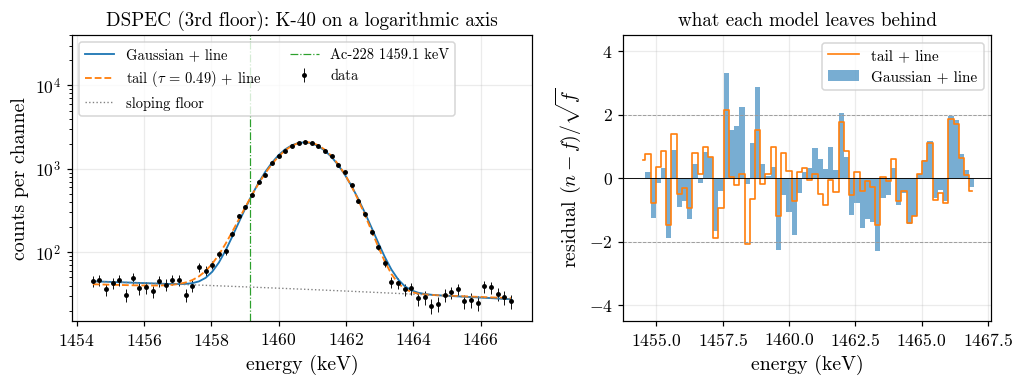

In [16]:
rows = []
for k, r in peak.items():
    x, y, sg = r["x"], r["y"], r["p"][2]
    gain = float(cal[k].gain(r["p"][1]))
    left, right = y[x < r["p"][1] - 4.5 * sg], y[x > r["p"][1] + 4.5 * sg]
    drop = left.mean() - right.mean()
    s_drop = np.sqrt(left.mean() / len(left) + right.mean() / len(right))
    floor = r["p"][3] + r["p"][4] * (x - r["x0"])                   # the straight floor of the Gaussian + line fit
    top = tilt_fits[(k, "tail + line")]["top"]
    wl, wr = (x >= top - 3 * sg) & (x < top - sg), (x > top + sg) & (x <= top + 3 * sg)
    NL, NR = (y - floor)[wl].sum(), (y - floor)[wr].sum()
    sL, sR = np.sqrt(y[wl].sum()), np.sqrt(y[wr].sum())
    rows.append({"detector": k, "floor left (counts/channel)": left.mean(), "floor right": right.mean(), "drop": drop,
                 "drop / error": drop / s_drop, "slope (counts/channel per keV)": r["p"][4] / gain,
                 "slope error": r["err"][4] / gain, "left wing (counts)": NL, "right wing (counts)": NR,
                 "asymmetry (L-R)/(L+R) %": 100 * (NL - NR) / (NL + NR),
                 "asymmetry error %": 100 * 2 * np.hypot(NR * sL, NL * sR) / (NL + NR)**2})
tilt_free = pd.DataFrame(rows).set_index("detector").T
print(tilt_free.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), gridspec_kw=dict(width_ratios=[1.25, 1]))
k, r = D1, peak[D1]
E = cal[k].energy(r["x"])
gfit, tfit = tilt_fits[(k, "Gaussian + line")], tilt_fits[(k, "tail + line")]
ax = axes[0]
ax.errorbar(E, r["y"], yerr=np.sqrt(np.maximum(r["y"], 1)), fmt="o", ms=2.2, color="k", elinewidth=0.6, label="data")
ax.plot(E, gfit["f"], color=COL[k], lw=1.2, label="Gaussian + line")
ax.plot(E, tfit["f"], color="tab:orange", lw=1.2, ls="--", label=fr"tail ($\tau$ = {TAU[k]:.2f}) + line")
ax.plot(E, gfit["p"][3] + gfit["p"][4] * (r["x"] - r["x0"]), color="0.5", lw=0.9, ls=":", label="sloping floor")
ax.axvline(AC228_E, color="tab:green", lw=0.8, ls="-.", label="Ac-228 1459.1 keV")
ax.set(yscale="log", xlabel="energy (keV)", ylabel="counts per channel", title=f"{k}: K-40 on a logarithmic axis", ylim=(15, 4e4))
ax.legend(fontsize=9.5, loc="upper left", ncol=2)
ax = axes[1]
width = float(cal[k].gain(r["p"][1]))
ax.bar(E, (r["y"] - gfit["f"]) / np.sqrt(gfit["f"]), width=width, color=COL[k], alpha=0.6, label="Gaussian + line")
ax.step(E, (r["y"] - tfit["f"]) / np.sqrt(tfit["f"]), where="mid", color="tab:orange", lw=1.1, label="tail + line")
ax.axhline(0, color="k", lw=0.6)
for yv in (-2, 2):
    ax.axhline(yv, color="0.6", lw=0.6, ls="--")
ax.set(xlabel="energy (keV)", ylabel=r"residual $(n-f)/\sqrt{f}$", ylim=(-4.5, 4.5), title="what each model leaves behind")
ax.legend(fontsize=10, loc="upper right")
fig.tight_layout(); save(fig, "k40_tilt"); plt.show()

### What makes the peak tilted
**Without a model.** On the DSPEC the floor is 40.9 counts per channel on the left of the peak and 31.1 on the right, a drop of $9.8 \pm 2.5$ (3.9 standard deviations), which corresponds to a slope of $-1.41 \pm 0.21$ counts per channel per keV. The floor is therefore tilted, as expected for a Compton continuum that falls with energy. The peak itself is lopsided as well. Between $1\sigma$ and $3\sigma$ from its top the left wing holds 3847 counts above the floor and the right wing 3463, an asymmetry of $5.3 \pm 1.2$ % (4.3 standard deviations). On the Lynx the floor drops by 1.6 counts per channel (2.2 standard deviations) and the asymmetry is $1 \pm 12$ %, so with 500 counts the tilt of the peak cannot be seen at all.

**With models (DSPEC).** The Gaussian on a sloping line fits poorly ($D = 89.1$ for 59 degrees of freedom, $p = 0.007$), and the residuals in the figure show the surplus on the low side. Each of the three low-side terms improves the fit when it is added alone, the step by $\Delta D = -23$, the Ac-228 neighbour by $-32$ and the tail by $-37$ (to $p = 0.74$). The tail does best, and it does so without a new free parameter, because its length $\tau = 0.49$ was measured from the other lines of this spectrum. Once the tail is in the model, the other two are no longer needed. The step is $7.5 \pm 8.5$ counts per channel and the Ac-228 area $0 \pm 120$ counts, both consistent with zero, and neither improves $D$ by even 1.

**The alternatives fail a physical check.** Fitted alone, the neighbour asks for $597 \pm 108$ counts of Ac-228. The Ac-228 line at 911.2 keV in the same spectrum predicts only 75 to 100 counts at 1459.1 keV (0.3 to 0.4 % of K-40), six to eight times less. The step fitted alone is 40 counts per channel, but it turns the slope of the floor from $-0.28$ to $+0.56$ counts per channel per channel, that is a floor rising with energy, which a Compton continuum cannot do. Both terms are standing in for the tail. The step and the neighbour are still real effects, but at their expected size they are below what this peak can resolve (an uncertainty of 120 counts on Ac-228 against 75 to 100 expected).

**So the tilt has two parts.** The floor is tilted by the falling Compton continuum, which the straight line $b_0 + b_1(i - x_0)$ describes, and the peak is tilted by the low-energy tail from incomplete charge collection, which the EMG describes. On a logarithmic axis (left panel) the tail shows as a left wing that falls along a straight line while the right wing follows the Gaussian parabola. On a linear axis the same thing appears as a fuller left side.

**How we cope with it.**
1. Fit raw counts on a linear scale with a symmetric window, so that the floor is fixed by both flanks and its slope is a fitted parameter, not an assumption.
2. Use the tailed model with $\tau$ measured from the strong lines of each detector. Then quote the mode (the visible top) as the position, 0.22 channel (44 eV) above the Gaussian centre here, and the area of the whole peak including its tail, 0.37 % above the Gaussian area.
3. Treat the step and the neighbour as systematic errors. Adding the step to the tailed model changes the area by 0.08 %, and an Ac-228 line of the predicted size would take 0.3 to 0.4 % of it. Both are below the 0.7 % statistical error.
4. For a weak peak none of this can be measured from the peak itself (every $\Delta D$ on the Lynx is below 0.3), so its shape must be taken from strong lines of the same detector.

## 13. Is our fit the same as InterSpec's, and which is better?

### Why
The lab script recommends InterSpec for the many peaks of the forensic part, and both demonstrators said to use it once one peak is understood ("you agree with what InterSpec is giving, then we start to use these tools", 13 October). So we need to know what InterSpec does differently from our fit, how large the difference is, and which of the two to trust when they disagree.

### What InterSpec does, next to what we do
InterSpec's method is described in its help files and its source code (session 2, Section 14, has the full table). For a single isolated peak the two fits share almost everything. Both use a Gaussian integrated over each channel, a straight-line continuum by default, and a non-linear minimiser. Three things differ.

| | InterSpec (default) | Our fit |
|---|---|---|
| What is minimised | $\chi^2 = \sum_i (n_i - f_i)^2/n_i$, least squares weighted by the **observed** counts (Neyman's $\chi^2$) | the Poisson deviance $D$, that is maximum likelihood |
| Peak shape | Gaussian (skewed shapes are optional) | Gaussian in Table 1, tail (EMG) for positions and for the line table |
| Fit region | chosen by its peak search, about $\pm 2.7$ FWHM here | chosen by the rule of Section 3, $\pm 7\sigma$ or $\pm 8\sigma$ |

### Why the statistic matters
Counts are Poisson distributed, with variance equal to the **expected** count $f_i$. Neyman's $\chi^2$ replaces $f_i$ by the observed $n_i$. A channel that happened to fluctuate low is then given a small variance and a large weight, and one that fluctuated high a small weight, so the fit is pulled towards the low channels. For a continuum of $b$ counts per channel the bias is close to $-1$ count per channel whatever $b$ is. Relative to $b$ it is negligible when $b$ is hundreds and large when $b$ is a few. A continuum that is fitted too low leaves too many counts for the peak, so the area comes out too high. Maximum likelihood uses the Poisson probability itself and has no such bias.

### Method
1. Refit both K-40 peaks in the same window with the same model, changing only the statistic, so that any difference is due to the statistic alone.
2. Simulate peaks with known area (500 per case) and fit each with both statistics. With the truth known, the bias of each is measured directly, which is the demonstrator's test (10:13).
3. Compare with the real InterSpec output for the four Lynx spectra, read from InterSpec 1.0.12 on 27 October (`data/interspec/session2/`). InterSpec has not yet been run on the DSPEC background.
4. Recall the eleven ways of fitting one peak that were compared in session 1 after the first feedback, on simulated peaks with the counts of a four-day and of a one-hour run.

In [17]:
rows = []
for k, r in peak.items():
    lo, hi, mu, sg = int(r["x"][0]), int(r["x"][-1]), r["p"][1], r["p"][2]
    for name, st in (("Poisson likelihood (ours)", "poisson"), ("Neyman chi2 (InterSpec)", "neyman")):
        f = fit_shape(spec[k].counts, lo, hi, mu, sg, statistic=st)
        rows.append(dict(detector=k, statistic=name, A=f["p"][0], sA=f["err"][0], mu=f["p"][1], smu=f["err"][1],
                         FWHM_keV=G.FWHM_PER_SIGMA * f["p"][2] * float(cal[k].gain(f["p"][1])), floor_b0=f["p"][3], s_b0=f["err"][3]))
stat_data = pd.DataFrame(rows)
print("the same K-40 data, the same window and model, two statistics")
table(stat_data, 3)

N_STAT_TOYS = 500
rng_stat = np.random.default_rng(SEED + 1)
weak = peak[D2]["p"].copy()
weak[0] = 100.0                                                     # a weak line on the Lynx K-40 floor
truths = {"K-40 as on the 3rd floor (23 000 counts)": (peak[D1]["p"], peak[D1]),
          "K-40 as in the basement (500 counts)": (peak[D2]["p"], peak[D2]), "weak line (100 counts)": (weak, peak[D2])}
rows = []
for label, (ptrue, r) in truths.items():
    x, lo, hi = r["x"], int(r["x"][0]), int(r["x"][-1])
    lam = model(ptrue, x, r["x0"], 2, "gauss", 0.0)
    got = {"poisson": [], "neyman": []}
    for _ in range(N_STAT_TOYS):
        y = np.zeros(hi + 2)
        y[lo:hi + 1] = rng_stat.poisson(lam)
        for st in got:
            f = fit_shape(y, lo, hi, ptrue[1], ptrue[2], statistic=st)
            got[st].append((f["p"][0], f["err"][0], f["p"][3]))
    for st, v in got.items():
        v = np.array(v)
        rows.append({"simulated truth": label, "statistic": st, "floor (counts/channel)": ptrue[3],
                     "bias of floor": v[:, 2].mean() - ptrue[3], "bias of area (%)": 100 * (v[:, 0].mean() - ptrue[0]) / ptrue[0],
                     "its error (%)": 100 * v[:, 0].std() / np.sqrt(len(v)) / ptrue[0],
                     "pull width of area": ((v[:, 0] - ptrue[0]) / v[:, 1]).std(ddof=1)})
stat_toys = pd.DataFrame(rows)
print(f"\n{N_STAT_TOYS} simulated peaks per case with known truth")
table(stat_toys, 3)

the same K-40 data, the same window and model, two statistics
         detector                 statistic         A      sA       mu   smu  FWHM_keV  floor_b0  s_b0
DSPEC (3rd floor) Poisson likelihood (ours) 23189.278 158.320 7409.854 0.032     2.093    36.168 1.012
DSPEC (3rd floor)   Neyman chi2 (InterSpec) 23176.726 158.075 7409.856 0.032     2.089    34.999 0.995
  Lynx (basement) Poisson likelihood (ours)   499.853  27.585 8674.000 0.306     2.097     5.460 0.322
  Lynx (basement)   Neyman chi2 (InterSpec)   529.403  26.887 8673.968 0.299     2.250     3.738 0.275



500 simulated peaks per case with known truth
                         simulated truth statistic  floor (counts/channel)  bias of floor  bias of area (%)  its error (%)  pull width of area
K-40 as on the 3rd floor (23 000 counts)   poisson                  36.168         -0.009             0.035          0.030               0.976
K-40 as on the 3rd floor (23 000 counts)    neyman                  36.168         -0.972             0.044          0.030               0.978
    K-40 as in the basement (500 counts)   poisson                   5.460         -0.037             0.067          0.242               0.982
    K-40 as in the basement (500 counts)    neyman                   5.460         -1.190             1.303          0.258               1.072
                  weak line (100 counts)   poisson                   5.460         -0.013             2.117          0.842               1.032
                  weak line (100 counts)    neyman                   5.460         -1.195      

In [18]:
isp = pd.read_csv(ROOT / "results" / "session2" / "s2_interspec_comparison.csv")
isp = isp[isp.note.isna()].copy()                                   # drop the 36 keV continuum step, which is not a peak
isp["ratio_tail"], isp["ratio_gauss"] = isp.area_interspec / isp.area_ours_emg, isp.area_interspec / isp.area_ours_gauss
rows = []
for name, d in isp[isp.signif > 10].groupby("spectrum", sort=False):
    rows.append({"Lynx spectrum": name, "strong peaks": len(d), "mean energy difference (eV)": 1000 * d.dE_keV.mean(),
                 "scatter (eV)": 1000 * d.dE_keV.std(), "area InterSpec / ours (tail)": d.ratio_tail.median(),
                 "area InterSpec / ours (Gaussian)": d.ratio_gauss.median(), "FWHM InterSpec / ours": (d.fwhm_interspec / d.fwhm_ours).median()})
isp_summary = pd.DataFrame(rows)
print("real InterSpec 1.0.12 output against our fits at the same energies, peaks above 10 standard deviations")
table(isp_summary, 3)
weak_peaks = isp[(isp.signif <= 10) & isp.in_our_inventory.astype(bool)]
print(f"weaker peaks that both programs find ({len(weak_peaks)}): median area ratio InterSpec / ours = {weak_peaks.ratio_gauss.median():.2f}")

k40_isp = isp[(isp.E_interspec - K40).abs() < 0.5][["spectrum", "E_interspec", "fwhm_interspec", "fwhm_ours", "area_interspec",
                                                    "s_area_interspec", "area_ours_gauss", "area_ours_emg", "s_area_ours"]]
print("\nK-40 in the four Lynx spectra")
table(k40_isp, 3)
ours, s_ours = peak[D2]["p"][0], peak[D2]["err"][0]
ib = k40_isp[k40_isp.spectrum == "background"].iloc[0]
print(f"Lynx background K-40: InterSpec {ib.area_interspec:.0f} +- {ib.s_area_interspec:.0f}, our Table 1 fit {ours:.0f} +- {s_ours:.0f} counts, "
      f"difference {(ib.area_interspec - ours) / s_ours:+.2f} of our statistical error (same data, so not an independent pull)")

cols = ["method", "bias mu", "RMS mu", "pull sd mu", "bias A", "RMS A", "pull sd A"]
for label, name in (("four-day run (23 000 counts in K-40)", "s1_k40_toy_study_4day.csv"), ("one-hour run (240 counts)", "s1_k40_toy_study_1hour.csv")):
    print(f"\nsession 1: methods of fitting one peak on simulated K-40 peaks, {label}")
    table(pd.read_csv(ROOT / "results" / "session1" / name)[cols], 3)

real InterSpec 1.0.12 output against our fits at the same energies, peaks above 10 standard deviations
Lynx spectrum  strong peaks  mean energy difference (eV)  scatter (eV)  area InterSpec / ours (tail)  area InterSpec / ours (Gaussian)  FWHM InterSpec / ours
   background             6                       -9.667        27.593                         1.030                             1.035                  1.022
     IAEA-385            18                      -14.436        15.421                         1.012                             1.016                  1.013
     Norway 1            12                       -6.973        31.491                         1.004                             1.021                  1.007
     Norway 2            15                       -9.132        14.543                         1.002                             1.030                  1.026
weaker peaks that both programs find (3): median area ratio InterSpec / ours = 1.17

K-40 in the four Lynx 

### What the comparison shows
**The same data with the two statistics.** For the strong DSPEC peak the statistic does not matter. The area changes by 13 counts out of 23 189 (0.05 %, a twelfth of the statistical error) and the centre by 0.002 channel. For the weak Lynx peak it does. Neyman's $\chi^2$ puts the floor at 3.7 counts per channel where the likelihood puts it at 5.5, and gives 529 counts in the peak where the likelihood gives 500, 5.9 % or 1.1 statistical errors more, with a peak that is 7 % wider.

**Simulated peaks with a known answer.** Neyman's $\chi^2$ places the floor $0.97$ to $1.20$ counts per channel too low in all three cases, as the argument above predicts, while the likelihood has no bias (below 0.04). What this does to the area depends on the counts. It is harmless for 23 000 counts ($+0.04$ %), $+1.3$ % for a peak like the Lynx K-40 and $+8.8$ % for a line of 100 counts, and the quoted errors become too small (pull widths of 1.07 and 1.26). The likelihood gives $+0.07 \pm 0.24$ % at 500 counts with a pull width of 0.98. At 100 counts it shows a small bias of its own, $+2.1 \pm 0.8$ %, which comes from letting the width of a four-standard-deviation peak float. That is the reason why the weak lines of Table 2 are fitted with the width fixed. The sign of the Neyman bias is not universal. It removes about one count per channel from the whole window. With a floor of several counts per channel the floor absorbs it and the peak gains, as here, but in the one-hour simulation of session 1, where the floor is nearly empty, the peak itself lost 8 % (table above, $-19.9$ counts).

**The real InterSpec output.** For peaks above 10 standard deviations in the four Lynx spectra, InterSpec's energies are 7 to 14 eV below ours on average, with a scatter of 15 to 30 eV, its areas are 0.2 to 3.0 % above our tailed fits and 1.6 to 3.5 % above our Gaussian fits, and its widths 1 to 3 % larger. For the three weaker peaks that both programs find, InterSpec's areas are 17 % larger. For K-40 in the Lynx background InterSpec gives $505 \pm 26$ counts and our Table 1 fit $500 \pm 28$. This is closer than the 529 of our own Neyman fit, because InterSpec chose a narrower region (1454.8 to 1466.1 keV), which contains fewer low-count floor channels for the bias to act on.

**Which way of fitting is best.** Session 1 compared eleven methods on simulated K-40 peaks. For a four-day run, Neyman's $\chi^2$, Pearson's $\chi^2$, the Poisson likelihood and the mixture model all reach the same precision (0.031 channel and 159 counts, the statistical limit) with correct errors. Unweighted least squares is nearly as precise but quotes errors that are half the real scatter (pull width 2.1). The linearised fit of a parabola to the logarithm of the counts wastes half the information (RMS 0.048 channel and 225 counts), simple counting in a region loses 68 counts to the wings, and reading off the highest channel is 20 times less precise. For a one-hour run the methods separate, and only the likelihood (and the mixture model, which maximises the same likelihood) stays unbiased with correct errors.

**Answer.** Our fit and InterSpec's are the same model with a different statistic and, by default, a different peak shape. They agree to 0.2 to 3 % in area and about 10 eV in energy for strong peaks, where either can be used. For weak peaks on a low continuum, which is the situation of every forensic line in the basement, the Poisson likelihood is the better choice because it is unbiased, and InterSpec's areas should be expected to come out high by several per cent. The systematic difference in energy has a different origin. InterSpec quotes the mean of a Gaussian and we quote the top of a tailed peak, which Section 5 showed to lie apart.

## 14. One line, two numbers: the K-40 rates of Table 1 and Table 2

### Why
The first draft quoted the K-40 rate twice. Table 1 (the peak "done properly") gave $170 \pm 9$ counts per day for the Lynx and Table 2 (every line in both backgrounds) gave $160 \pm 9$. For the DSPEC the two were 5973 and 5994. A reader who sees two values for one quantity will ask which is right, so the difference has to be traced to its cause.

### What differs between the two fits
Table 1 is the demonstrator's fit, a Gaussian whose width is a free parameter, in the window chosen in Section 3. Table 2 measures weak and strong lines in the same way, which needs a shape that does not depend on the line's own statistics. There the tail is included and the width is **fixed** to the detector's resolution curve of Section 6, in a window of $\pm 7\sigma$. The cell below changes one thing at a time, from the first fit to the second.

In [19]:
rows = []
for k in (D1, D2):
    r = peak[k]
    gain = float(cal[k].gain(cal[k].channel(K40)))
    rows.append(dict(detector=k, fit="Table 1: Gaussian, width free (Section 3)", half_window=HALF[k], A=r["p"][0], sA=r["err"][0],
                     FWHM_keV=G.FWHM_PER_SIGMA * r["p"][2] * gain))
    steps = [("tail instead of Gaussian, width free", dict(free_width=True, half=HALF[k])),
             ("tail, width fixed to the resolution curve", dict(free_width=False, half=HALF[k])),
             ("Table 2: the same in a 7 sigma window", dict(free_width=False, half=7.0))]
    for name, kw in steps:
        p, _ = G.fit_line_at(spec[k], cal[k], K40, sigma_model[k], TAU[k], **kw)
        rows.append(dict(detector=k, fit=name, half_window=kw["half"], A=p["A"], sA=p["sA"], FWHM_keV=p["fwhm"] * gain))
ladder = pd.DataFrame(rows)
ladder["counts per day"] = [86400 * a / spec[k].live for a, k in zip(ladder.A, ladder.detector)]
ladder["error"] = [86400 * a / spec[k].live for a, k in zip(ladder.sA, ladder.detector)]
table(ladder, 3)
for k in (D1, D2):
    d = ladder[ladder.detector == k]
    free = d.iloc[1]
    model_fwhm = float(G.fwhm_model(K40, *RES_FULL[k]))
    print(f"{k}: resolution curve predicts {model_fwhm:.3f} keV at 1460.8 keV, this peak fitted alone gives {free.FWHM_keV:.3f} keV; "
          f"Table 2 / Table 1 = {d.iloc[-1].A / d.iloc[0].A:.3f}, difference {abs(d.iloc[-1].A - d.iloc[0].A) / d.iloc[0].sA:.1f} statistical errors")
print(f"ratio of the K-40 rates, 3rd floor / basement: {ladder.iloc[0]['counts per day'] / ladder.iloc[4]['counts per day']:.1f} (Table 1), "
      f"{ladder.iloc[3]['counts per day'] / ladder.iloc[7]['counts per day']:.1f} (Table 2)")

         detector                                       fit  half_window         A      sA  FWHM_keV  counts per day  error
DSPEC (3rd floor) Table 1: Gaussian, width free (Section 3)          7.0 23189.278 158.320     2.093        5972.606 40.777
DSPEC (3rd floor)      tail instead of Gaussian, width free          7.0 23277.842 159.372     2.065        5995.416 41.048
DSPEC (3rd floor) tail, width fixed to the resolution curve          7.0 23273.111 158.110     2.062        5994.197 40.723
DSPEC (3rd floor)     Table 2: the same in a 7 sigma window          7.0 23273.111 158.110     2.062        5994.197 40.723
  Lynx (basement) Table 1: Gaussian, width free (Section 3)          8.0   499.853  27.585     2.097         170.232  9.394
  Lynx (basement)      tail instead of Gaussian, width free          8.0   499.941  28.095     2.080         170.262  9.568
  Lynx (basement) tail, width fixed to the resolution curve          8.0   478.448  25.602     1.851         162.942  8.719
  Lynx (

### Why the two tables differ
**DSPEC.** Replacing the Gaussian by the tailed shape raises the area from 23 189 to 23 278 counts (0.4 %), and nothing else changes it, because the resolution curve predicts 2.062 keV for this line and the peak fitted alone gives 2.065 keV. The whole difference between 5973 and 5994 counts per day is the tail, the 0.4 % shape effect of Section 4, and it is half a statistical error.

**Lynx.** Here the tail changes nothing (500 counts either way), but fixing the width does. The resolution curve, which is dominated by the strong lines of the IAEA-385 and Norway spectra, predicts 1.85 keV at 1460.8 keV, while this particular peak fitted alone is $2.08 \pm 0.11$ keV wide. A shape that is too narrow cannot collect the outer counts, so the area falls by 4.3 % to 478, and the narrower window of Table 2 takes another 1.8 %, to 470. Together Table 2 is 6.0 % (1.1 statistical errors) below Table 1.

**Which to use.** For K-40 itself Table 1 is the better number, because the peak is strong enough to determine its own width. Table 2 exists to treat all lines alike, weak ones included, and for that the fixed shape is necessary (Section 13 showed what a free width does to a weak peak). The price is a systematic error of a few per cent for any line whose width in that run differs from the curve, which is small against the 4 to 90 % statistical errors of the Lynx lines. Section 16 shows that this peak's larger width is an ordinary fluctuation. The ratio of the K-40 rates on the two floors is 35.1 from Table 1 and 37.5 from Table 2, so the report quotes "35 to 38" and says which table is which.

## 15. Cs-137 in the third-floor background

### Why
Cs-137 (half-life 30.1 years, γ ray at 661.657 keV) is man-made. In the Norway sediments it is the line that carries the forensic argument, because it dates a layer through the deposition from weapons tests and from Chernobyl. Table 2 shows it in the third-floor background as well. A background line at the energy of the signal has two consequences. It must be subtracted, which adds its error, and it raises the smallest sample activity that can be seen. So we check that the line is real, compare the two detectors, and compare both with the Cs-137 rates of the sediments.

### Where it can come from
Cs-137 is not part of the natural decay chains, so it cannot come from rock or radon. The candidates are fallout Cs-137 in dust, soil and building materials around the detector, contamination of the shield or the detector surroundings from earlier samples, and sealed Cs-137 teaching sources stored in the same laboratory. The spectrum alone cannot separate these. What it can say is whether the line behaves like the other lines from outside the shield (strongly reduced in the basement) or like something inside it.

In [20]:
CS137 = 661.657
rows = []
for k in (D1, D2):
    p, fit = G.fit_line_at(spec[k], cal[k], CS137, sigma_model[k], TAU[k])
    pw, _ = G.fit_line_at(spec[k], cal[k], CS137, sigma_model[k], TAU[k], free_width=True)
    gain = float(cal[k].gain(cal[k].channel(CS137)))
    rows.append({"detector": k, "counts per day": 86400 * p["rate"], "error": 86400 * p["s_rate"], "significance": p["rate"] / p["s_rate"],
                 "fitted energy (keV)": p["E_fit"], "FWHM free (keV)": pw["fwhm"] * gain, "its error": pw["sfwhm"] * gain,
                 "FWHM from curve (keV)": float(G.FWHM_PER_SIGMA * sigma_model[k](CS137)),
                 "rate + 2 sigma (counts per day)": 86400 * (max(p["rate"], 0) + 2 * p["s_rate"]), "D": fit["dev"], "ndf": fit["ndf"]})
cs = pd.DataFrame(rows).set_index("detector")
print(cs.T.round(3).to_string())

net2 = pd.read_csv(ROOT / "results" / "session2" / "s2_net_rates.csv")
cs_samples = net2[net2.line.str.startswith("Cs-137")][["spectrum", "gross_cpd", "bkg_cpd", "net_cpd", "s_net_cpd", "bkg_share_pct"]]
print("\nCs-137 in the samples on the Lynx (session 2), counts per day")
table(cs_samples, 2)

detector                         DSPEC (3rd floor)  Lynx (basement)
counts per day                             152.907            8.536
error                                       15.206            6.624
significance                                10.056            1.289
fitted energy (keV)                        661.619          661.851
FWHM free (keV)                              1.325            0.404
its error                                    0.172            0.284
FWHM from curve (keV)                        1.498            1.269
rate + 2 sigma (counts per day)            183.319           21.784
D                                           38.289           41.816
ndf                                         43.000           43.000

Cs-137 in the samples on the Lynx (session 2), counts per day
spectrum  gross_cpd  bkg_cpd  net_cpd  s_net_cpd  bkg_share_pct
IAEA-385     351.34     8.54   342.80      13.18           2.43
Norway 1     242.85     8.54   234.31      13.84           3.

### What the Cs-137 line tells us
**It is real on the third floor.** The DSPEC background has $153 \pm 15$ counts per day at 661.7 keV, 10 standard deviations. The fitted energy is 661.62 keV, 38 eV from the Cs-137 energy and inside the 43 eV calibration systematic, and the width fitted alone is $1.33 \pm 0.17$ keV against 1.50 keV from the resolution curve (1.0 standard deviation). Energy and width are both those of a γ line at 661.7 keV. In the basement the rate is $8.5 \pm 6.6$ counts per day, not significant, so we quote an upper limit of 22 counts per day (rate plus two standard deviations).

**It behaves like a line from outside the shield.** The basement rate is at least 7 times lower, in line with K-40 (35 to 38) and Tl-208 at 583 keV (more than 30) and unlike the radon daughters inside the shield (4 to 17). So the Cs-137 reaches the third-floor detector from its surroundings, through a thinner shield. Whether that is fallout Cs-137 in dust and building materials or a sealed source stored in the laboratory, the spectrum cannot say. This is a question for the demonstrator.

**Why it matters for the sediments.** On the Lynx the Cs-137 background is only 3.5 % (Norway 1) and 5.2 % (Norway 2) of the gross rate with the sample in place, so the sediment line is measured almost free of background and its error is the sample's own counting error. The third-floor background alone, 153 counts per day, is as large as the entire net Cs-137 signal of Norway 2 on the Lynx (155 counts per day). The two detectors have different efficiencies, so this is a comparison of orders of magnitude only, but it means that on the DSPEC about half of the Cs-137 counts would be background, to be subtracted with its own error. If our detector is repaired, Cs-137 should still be measured in the basement, or the third-floor measurement needs a background run as long as the sample run.

## 16. Is the Lynx stable from run to run?

### Why
The Lynx was run with its gain stabiliser off (settings photographed on 27 October), and each run lasts two to four days. If the gain drifts during a run, every peak is smeared along the energy axis and looks wider. If it drifts between runs, a calibration from one run is wrong for the next. Session 3 also found the K-40 line wider in our two-day run of Norway 2 than in the four-day run of the same pot, which a gain drift could explain. Five Lynx runs taken over two weeks let us test both.

### What a gain drift would do
A change of gain by a fraction $\delta$ moves a line at energy $E$ by $\delta E$. Between runs this shows as a shift of every line in proportion to its channel number. Within a run, a drift spread evenly over a range $\delta$ adds a rectangular smear of standard deviation $\delta E/\sqrt{12}$, so the extra width grows in proportion to $E$, and the line at 2614.5 keV must broaden 1.8 times more than K-40. A change of noise or of charge collection would have a different energy dependence.

### Method
Each of the five runs is calibrated by itself as in Section 2, and four strong lines (352, 609, 1461 and 2614.5 keV) are fitted with free width. We compare (a) the channel positions between runs, in parts per million of the channel number, (b) the widths of each line across the runs, with a $\chi^2$ against their weighted mean, and (c) the K-40 broadening of our two-day run against what a drift would then predict at 2614.5 keV.

In [21]:
LYNX_RUNS = {"background": BACKGROUNDS[D2], "IAEA-385": LYNX_REFERENCE, "Norway 1": LYNX_OTHERS[0], "Norway 2 (3.97 d)": LYNX_OTHERS[1],
             "Norway 2 (1.96 d, ours)": ROOT / "data" / "raw" / "run_hpge_Tuesday_testrun.csv"}
CHECK_LINES = [351.932, 609.321, 1460.820, 2614.511]
rows = []
for name, path in LYNX_RUNS.items():
    s = G.read_spectrum(path)
    c = calibrate(s, TAU[D2], calib["IAEA-385 (Lynx)"]["cal"])
    for E in CHECK_LINES:
        p, _ = G.fit_line_at(s, c["cal"], E, sigma_model[D2], TAU[D2], free_width=True)
        gain = float(c["cal"].gain(c["cal"].channel(E)))
        rows.append(dict(run=name, live_d=s.live / 86400, E=E, channel=p["position"], s_channel=p["sposition"],
                         fwhm=p["fwhm"] * gain, s_fwhm=p["sfwhm"] * gain))
stab = pd.DataFrame(rows)
order = list(LYNX_RUNS)
pos = stab.pivot(index="run", columns="E", values="channel").loc[order]
s_pos = stab.pivot(index="run", columns="E", values="s_channel").loc[order]
print("position of each line relative to the IAEA-385 run, parts per million of the channel number (error in brackets)")
ppm, s_ppm = 1e6 * (pos / pos.loc["IAEA-385"] - 1), 1e6 * np.sqrt(s_pos**2 + s_pos.loc["IAEA-385"]**2) / pos
print((ppm.round(0).astype(int).astype(str) + " (" + s_ppm.round(0).astype(int).astype(str) + ")").to_string())

fw = stab.pivot(index="run", columns="E", values="fwhm").loc[order]
s_fw = stab.pivot(index="run", columns="E", values="s_fwhm").loc[order]
print("\nFWHM (keV) of each line in each run (error in brackets)")
print((fw.round(3).astype(str) + " (" + s_fw.round(3).astype(str) + ")").to_string())
rows = []
for E in CHECK_LINES:
    w = 1 / s_fw[E]**2
    mean = float((w * fw[E]).sum() / w.sum())
    chi2 = float((((fw[E] - mean) / s_fw[E])**2).sum())
    rows.append({"line (keV)": E, "weighted mean FWHM (keV)": mean, "chi2": chi2, "ndf": len(fw) - 1, "p": stats.chi2.sf(chi2, len(fw) - 1)})
width_test = pd.DataFrame(rows)
print()
table(width_test, 3)

long_, short_ = "Norway 2 (3.97 d)", "Norway 2 (1.96 d, ours)"
dk = fw.loc[short_, K40] - fw.loc[long_, K40]
s_dk = np.hypot(s_fw.loc[short_, K40], s_fw.loc[long_, K40])
extra = np.sqrt(max(fw.loc[short_, K40]**2 - fw.loc[long_, K40]**2, 0.0))        # extra FWHM in quadrature at 1460.8 keV
drift_ppm = 1e6 * extra / G.FWHM_PER_SIGMA * np.sqrt(12) / K40
pred = np.sqrt(fw.loc[long_, 2614.511]**2 + (extra * 2614.511 / K40)**2)
print(f"\nK-40 FWHM, two-day minus four-day run of Norway 2: {dk:+.3f} +- {s_dk:.3f} keV ({dk / s_dk:.1f} sigma)")
print(f"a gain drift would need a range of {drift_ppm:.0f} ppm within the run, against a run-to-run scatter of K-40 of {ppm[K40].std():.0f} ppm")
print(f"it would then make the 2614.5 keV line {pred:.2f} keV wide, measured {fw.loc[short_, 2614.511]:.2f} +- {s_fw.loc[short_, 2614.511]:.2f} keV "
      f"({(fw.loc[short_, 2614.511] - pred) / s_fw.loc[short_, 2614.511]:+.1f} sigma from that prediction)")

position of each line relative to the IAEA-385 run, parts per million of the channel number (error in brackets)
E                         351.932   609.321   1460.820  2614.511
run                                                             
background               -34 (103)   50 (77)    2 (37)  -24 (23)
IAEA-385                    0 (62)    0 (49)    0 (14)    0 (19)
Norway 1                   37 (73)  -33 (59)   -9 (21)   11 (21)
Norway 2 (3.97 d)         -35 (65)  -44 (50)  -21 (17)    7 (20)
Norway 2 (1.96 d, ours)  -152 (85)   46 (66)   37 (23)    1 (24)

FWHM (keV) of each line in each run (error in brackets)
E                             351.932        609.321        1460.820       2614.511
run                                                                                
background               1.018 (0.078)  1.369 (0.099)  2.033 (0.115)  2.602 (0.098)
IAEA-385                 1.097 (0.036)  1.354 (0.047)  1.859 (0.028)  2.521 (0.069)
Norway 1                 1.075 (0.047)  

### What the five runs show
**The gain does not drift between runs.** Relative to the IAEA-385 run, the lines of the other four runs sit within about 50 parts per million of their channel number, and within their errors. The only larger value is the 352 keV line of our two-day run ($-152 \pm 85$ ppm, 1.8 standard deviations). For K-40 the scatter over the five runs is 21 ppm, which is 0.03 keV or a fifth of a channel, over two weeks and without a stabiliser. Each spectrum is still calibrated by itself, because that costs nothing and removes even this, but a calibration carried over from another run would be wrong by far less than the per-line systematic of 80 to 170 eV.

**The widths are the same in every run.** For each of the four lines the five widths are consistent with one value ($\chi^2 = 2.1$, $2.1$, $5.5$ and $3.7$ for 4 degrees of freedom, $p$ from 0.24 to 0.73). This justifies pooling the Lynx runs for the resolution curve in Section 6.

**The K-40 width change is not a gain drift, and is probably not a change at all.** K-40 is $1.96 \pm 0.06$ keV wide in our two-day run and $1.84 \pm 0.04$ keV in the four-day run of the same pot, a difference of $0.118 \pm 0.075$ keV or 1.6 standard deviations. A gain drift large enough to cause it would have to cover 675 ppm within two days, thirty times the scatter seen between runs over two weeks, and it would widen the 2614.5 keV line to 2.76 keV, where $2.60 \pm 0.10$ keV is measured (1.6 standard deviations below that prediction). With five runs and four lines there are twenty widths, and one of them lying 1.6 standard deviations from another is expected. Session 3 flagged the K-40 width because it compared only these two runs. Seen with all five, it is a fluctuation. The same holds for the K-40 width of the background run ($2.03 \pm 0.12$ keV), which caused the difference between the two tables in Section 14.

**Consequence.** Runs of a few days on the Lynx need no stabiliser. The check is cheap and will be repeated for every new run, using the K-40 position and width as the monitor.

## 17. Numbers for the plans

### Why
Three of our planned steps depend on numbers that can be worked out now, namely how long a sealed pot needs before its radon daughters represent its radium, how to divide the remaining counting time between sample and background, and how much the unknown filling of the pots matters for the low-energy lines.

### Radon ingrowth after sealing
Ra-226 in the sediment decays to Rn-222, a gas with a half-life of 3.82 days. In an open pot part of the radon escapes, so its daughters Pb-214 and Bi-214, which are the lines we measure, under-report the radium. Once the pot is sealed, the radon inside grows back towards equilibrium as
$$ \frac{A_\mathrm{Rn}(t)}{A_\mathrm{Ra}} = 1 - 2^{-t/3.82\,\mathrm{d}}, $$
if we take the worst case in which all radon had escaped before sealing. Three weeks give 98 %, which is the usual rule, but only three sessions remain (17 and 24 November, 1 December).

### How to divide counting time
For a net rate $R_s - R_b$ measured for times $t_s$ (sample) and $t_b$ (background), the variance is $R_s/t_s + R_b/t_b$. For a fixed total time it is smallest when
$$ \frac{t_s}{t_b} = \sqrt{\frac{R_s}{R_b}}, $$
with $R_s$ the gross rate with the sample in place. A line with little background (Cs-137) wants almost all the time on the sample. A line that is mostly background (the radon daughters) wants equal times. The table uses the Norway 2 rates measured on the Lynx.

### Self-absorption and the filling of the pots
The efficiency measured with the IAEA-385 pot holds for the Norway pots only if they have the same geometry, density and filling height (lab script, Part B, Q4). A γ ray emitted at depth in the sample must cross the sediment above it. For a uniform layer of areal density $\rho h$ seen from one side, the fraction that emerges is
$$ T = \frac{1 - e^{-\mu\rho h}}{\mu\rho h}, $$
with $\mu$ the mass attenuation coefficient. We do not know the composition, so we take aluminium as a stand-in for silicate sediment (similar atomic number), with the NIST XCOM coefficients already used in the theory notes, and areal densities of 1 to 4 g cm$^{-2}$. This is a back-of-the-envelope estimate of where the masses and filling heights matter, not a correction.

In [22]:
T_RN = 3.8235                                                       # half-life of Rn-222 in days
seal = pd.Timestamp("2026-11-17")
rows = [{"measured on": (seal + pd.Timedelta(days=int(d))).strftime("%d %b"), "days after sealing on 17 Nov": int(d),
         "radon relative to equilibrium (%)": 100 * (1 - 2**(-d / T_RN))} for d in (0, 3, 7, 14, 21, 28)]
radon = pd.DataFrame(rows)
table(radon, 1)

n2 = net2[(net2.spectrum == "Norway 2") & (net2.net_cpd / net2.s_net_cpd > 3)].copy()
n2["best t_sample / t_background"] = np.sqrt(n2.gross_cpd / n2.bkg_cpd)
n2["sample share of 7 days (d)"] = 7 * n2["best t_sample / t_background"] / (1 + n2["best t_sample / t_background"])
print("\nNorway 2 on the Lynx: gross and background rates (counts per day) and the best division of counting time")
table(n2[["line", "gross_cpd", "bkg_cpd", "best t_sample / t_background", "sample share of 7 days (d)"]], 2)

xcom = pd.read_csv(ROOT / "data" / "reference" / "xcom_Z13.csv")
mu_al = lambda E_keV: float(np.exp(np.interp(np.log(E_keV / 1000), np.log(xcom.E_MeV), np.log(xcom.tot_without_coh))))
rows = []
for E in (46.539, 63.29, 186.2, 351.9, 661.7, 1460.8):
    r = {"E (keV)": E, "mu/rho (cm2/g)": mu_al(E)}
    for rho_h in (1.0, 2.0, 4.0):
        t = mu_al(E) * rho_h
        r[f"T at {rho_h:g} g/cm2"] = (1 - np.exp(-t)) / t
    t = mu_al(E) * 2.0
    r["change of T for +10 % in rho h (%)"] = 100 * 0.1 * (t * np.exp(-t) / (1 - np.exp(-t)) - 1)
    rows.append(r)
absorb = pd.DataFrame(rows)
print("\nfraction of gamma rays that leave a uniform layer (aluminium as a stand-in for sediment)")
table(absorb, 3)

measured on  days after sealing on 17 Nov  radon relative to equilibrium (%)
     17 Nov                             0                                0.0
     20 Nov                             3                               41.9
     24 Nov                             7                               71.9
     01 Dec                            14                               92.1
     08 Dec                            21                               97.8
     15 Dec                            28                               99.4

Norway 2 on the Lynx: gross and background rates (counts per day) and the best division of counting time
                line  gross_cpd  bkg_cpd  best t_sample / t_background  sample share of 7 days (d)
Ra-226 + U-235 186.0      91.51    16.56                          2.35                        4.91
        Pb-212 238.6     450.39    45.10                          3.16                        5.32
        Pb-214 295.2     297.39   120.44                  

### What the numbers mean for the plans
**Radon.** A pot sealed at the session of 17 November reaches 72 % of radon equilibrium by 24 November and 92 % by 1 December. The usual 98 % would be reached on 8 December, after our last session. Three weeks of sealing therefore no longer fit into the timetable. What does fit is to seal on 17 November (or to ask a demonstrator to seal earlier), to record the sealing time, to count the sealed pot in the last week, and to correct the Pb-214 and Bi-214 rates by the known ingrowth factor. The correction assumes that all radon had escaped before sealing, so it is an upper bound, and the two limits (no correction and full correction) bracket the Ra-226 activity. The 186 keV line of Ra-226 itself does not depend on radon and gives a cross-check, although it is weak and overlaps U-235.

**Counting time.** The best ratio of sample to background time is 4.4 for Cs-137, 3.2 for Pb-212, 1.8 for K-40 and 1.3 to 1.6 for the radon daughters. In a week between two sessions this means 4 to 5.7 days on the sample, so a split of about 4.5 days on the sample and 2.5 days on the empty shield serves all lines within a few per cent of their best precision. The background should be taken directly before or after the sample, because Section 10 found that radon in the shield changed by 2 % between two runs a few days apart. The dewar holds 30 L and loses about 2 L per day, and the detector must not be biased below 3 kg of nitrogen, so one filling lasts about 13 days. A weekly cycle is safe if the dewar is filled at each session, and we need to confirm who does this and whether runs may be left unattended.

**Self-absorption.** At 46.5 keV (Pb-210) a sediment layer of 1 to 4 g cm$^{-2}$ lets only 84 to 52 % of the γ rays out, and a 10 % difference in areal density between the reference pot and a sample pot changes the result by 3.3 %. At 661.7 keV (Cs-137) and 1460.8 keV (K-40) the same difference changes it by 0.7 % and 0.5 %, and the ratio of the two by only 0.2 %. So activity ratios of lines above about 300 keV are safe against the unknown filling at the 1 % level, which is why the mass-free ratios of sessions 2 and 3 are meaningful, while Pb-210 needs the mass and filling height of every pot. These are the numbers to ask the demonstrator for, as the script says they will be provided.

## 18. Extension from the lab script: a first limit on neutrinoless double beta decay

### Why
The script's extension points out that the detector itself contains a candidate for neutrinoless double beta decay ($0\nu\beta\beta$). Natural germanium is 7.75 % Ge-76, and if the decay exists, the two electrons deposit the full $Q_{\beta\beta} = 2039$ keV inside the crystal, which would appear as a narrow peak at that energy in the **background** spectrum. No peak means a lower limit on the half-life. We have two long backgrounds, so the limit costs nothing beyond what is already here, and it uses the same detection-limit formula as the minimum detectable activity that the third aim of the experiment asks for.

### Method
The number of background counts $B$ in a window of $\pm 3\sigma$ around 2039 keV (99.7 % of a peak) is summed from the channels. Currie's detection limit at 95 % confidence is
$$ L_D = k_\alpha^2 + 2k_\alpha\sqrt{2B}, \qquad k_\alpha = 1.645, $$
the smallest number of signal counts that would be told apart from a fluctuation of the background. The script's Eq. 6 turns $s = L_D$ into
$$ T_{1/2}^{0\nu} \geq \ln 2\;\frac{N_A\,a\,\eta\,m\,t}{W\,s}, $$
with $a$ the abundance of Ge-76, $W = 72.63$ g/mol, $m$ the crystal mass and $\eta$ the efficiency for containing both electrons, which is close to 1 for a decay inside the crystal. We do not know the crystal masses, so the limit is given per kilogram of germanium for $\eta = 1$, and scales in proportion to the real mass. A narrower window of $\pm 1.4\sigma$, which is the best compromise between losing signal and gaining background for a Gaussian peak on a flat floor, is shown for comparison. The window contains none of the lines of our reference table (the nearest feature there is the single-escape peak of Tl-208 at 2103.5 keV), and any weak line that is present is counted in $B$, which only makes the limit more cautious.

In [23]:
Q_BB, K_ALPHA, N_AVOGADRO, ABUNDANCE_76, W_GE = 2039.06, 1.645, 6.02214076e23, 0.0775, 72.63
rows = []
for k in (D1, D2):
    sigma_keV = float(sigma_model[k](Q_BB))
    for n_sigma, fraction in ((3.0, 0.9973), (1.4, 0.8385)):
        i0 = int(np.round(cal[k].channel(Q_BB - n_sigma * sigma_keV)))
        i1 = int(np.round(cal[k].channel(Q_BB + n_sigma * sigma_keV)))
        B = int(spec[k].counts[i0:i1 + 1].sum())
        width = float(cal[k].energy(i1 + 0.5) - cal[k].energy(i0 - 0.5))
        L_D = K_ALPHA**2 + 2 * K_ALPHA * np.sqrt(2 * B)
        years = spec[k].live / (365.25 * 86400)
        T = np.log(2) * N_AVOGADRO * ABUNDANCE_76 * (1000 / W_GE) * fraction * years / L_D
        rows.append({"detector": k, "window (sigma)": n_sigma, "window (keV)": width, "B (counts)": B,
                     "background (counts per keV per day)": B / width / (spec[k].live / 86400), "L_D (counts)": L_D,
                     "live time (d)": spec[k].live / 86400, "T_half limit per kg (1e19 yr)": T / 1e19})
bb = pd.DataFrame(rows)
table(bb, 3)

         detector  window (sigma)  window (keV)  B (counts)  background (counts per keV per day)  L_D (counts)  live time (d)  T_half limit per kg (1e19 yr)
DSPEC (3rd floor)             3.0         5.716         377                               16.987        93.046          3.883                          5.075
DSPEC (3rd floor)             1.4         2.759         197                               18.387        68.011          3.883                          5.837
  Lynx (basement)             3.0         5.393          90                                5.684        46.846          2.936                          7.623
  Lynx (basement)             1.4         2.528          43                                5.793        33.216          2.936                          9.039


### What the limit is, and what limits it
In a window of $\pm 3\sigma$ around 2039 keV the third-floor background holds 377 counts in 3.88 days (17.0 counts per keV per day) and the basement background 90 counts in 2.94 days (5.7 counts per keV per day). The detection limits are 93 and 47 counts, and the half-life limits $5.1\times10^{19}$ and $7.6\times10^{19}$ years per kilogram of germanium, or $5.8\times10^{19}$ and $9.0\times10^{19}$ with the narrower window. The basement detector gives the better limit although it ran for less time, because its background at 2 MeV is three times lower. The limit grows as $t/L_D$, and since $L_D \approx 2k_\alpha\sqrt{2B}$ with $B$ proportional to $t$, only as $\sqrt{t/b}$ for a background rate $b$. Counting four times longer gains a factor of two, and so does a background four times lower.

For a crystal of the order of 1 kg the limit is about $10^{20}$ years, $10^{10}$ times the age of the universe, and a factor of ten below the $10^{21}$ years that the script mentions for a few days of data, because our background at 2039 keV is higher than that estimate assumes. LEGEND reaches $10^{26}$ years with enriched germanium underground, where the background in the window is close to zero and the limit grows in proportion to $t$ itself. The lesson is the same as for the minimum detectable activity of the sediments. Beyond a few days, lower background is worth more than longer counting. To turn the number into a result we need the crystal masses, and the window can be widened to several background runs added together.

## 19. Which line has the worst uncertainty? Predicting errors before fitting, and pulls

### Why
On 13 October the demonstrator said that with some intuition we "should be able to tell which peak is going to have the worst uncertainty" before fitting it, and on 3 November that a predicted error is "always a good comparison". Section 3 did this for K-40. Here it is done for every line of Table 2, so that the table of rates comes with a check that needs no fit.

### The prediction
The error of a peak area is a counting error. If the background under the peak were known exactly it would be $\sqrt{A + B}$, with $B$ the background counts under the peak. If the background has to be estimated from about as many channels as the peak covers, it is $\sqrt{A + 2B}$. A fit with wide flanks and a fixed shape, as used for Table 2, lies between the two. The relative error $\sqrt{A + 2B}/A$ is therefore large for a weak line on a high continuum and small for a strong line on a low one. Since the continuum falls steeply with energy, a weak line at low energy is the worst case and a strong line at high energy the best. $B$ is taken from the raw counts within $\pm 2.5\sigma$ of the line, minus the fitted area.

### Pulls
The script's measure of agreement between two numbers is the pull $Z = (x_1 - x_2)/\sqrt{\sigma_1^2 + \sigma_2^2}$, with $|Z| \lesssim 1$ consistent, about 2 in tension and above 3 inconsistent. It is applied to the quantities the two detectors should share.

In [24]:
rows = []
for name, E, nb in LINES:
    if name == "annihilation":
        continue                                                    # Doppler broadened, fitted with a free width
    row = lines_tab[lines_tab.E == E].iloc[0]
    for k, tag in ((D1, "1"), (D2, "2")):
        A, sA = row[f"cpd{tag}"] * spec[k].live / 86400, row[f"s_cpd{tag}"] * spec[k].live / 86400
        centre = float(cal[k].channel(E))
        sg = float(sigma_model[k](E)) / float(cal[k].gain(centre))
        lo_, hi_ = int(np.round(centre - 2.5 * sg)), int(np.round(centre + 2.5 * sg))
        N = spec[k].counts[lo_:hi_ + 1].sum()
        beta = TAU[k] * sg                                             # the tailed peak, whose top sits at the line energy
        mu_ = centre - G.emg_mode(0.0, sg, beta)
        frac = float(G.emg_cdf(hi_ + 0.5, mu_, sg, beta) - G.emg_cdf(lo_ - 0.5, mu_, sg, beta))
        B = max(N - frac * max(A, 0.0), 0.0)                           # continuum counts under the peak window
        rows.append({"line": f"{name} {E:.1f}", "detector": k, "A": A, "B": B, "sqrt(A+B)": np.sqrt(max(A, 0) + B),
                     "sqrt(A+2B)": np.sqrt(max(A, 0) + 2 * B), "fitted error": sA,
                     "predicted relative error (%)": 100 * np.sqrt(max(A, 0) + 2 * B) / A if A > 0 else np.nan,
                     "fitted relative error (%)": 100 * sA / A if A > 0 else np.nan})
pred = pd.DataFrame(rows)
pred["inside the two bounds"] = (pred["fitted error"] >= pred["sqrt(A+B)"]) & (pred["fitted error"] <= pred["sqrt(A+2B)"])   # strict, no tolerance
pred["miss (%)"] = np.where(pred["inside the two bounds"], 0.0,
                            100 * np.where(pred["fitted error"] < pred["sqrt(A+B)"], pred["fitted error"] / pred["sqrt(A+B)"] - 1,
                                           pred["fitted error"] / pred["sqrt(A+2B)"] - 1))
for k in (D1, D2):
    print(f"\n{k}, lines ordered from the worst predicted relative error to the best")
    table(pred[pred.detector == k].drop(columns="detector").sort_values("predicted relative error (%)", ascending=False), 2)
rank = pred.dropna()
print(f"\nrank correlation between predicted and fitted relative errors: {stats.spearmanr(rank['predicted relative error (%)'], rank['fitted relative error (%)'])[0]:.3f}; "
      f"{int(pred['inside the two bounds'].sum())} of {len(pred)} fitted errors lie strictly between sqrt(A+B) and sqrt(A+2B); "
      f"the others miss by {pred.loc[~pred['inside the two bounds'], 'miss (%)'].abs().min():.1f} to {pred.loc[~pred['inside the two bounds'], 'miss (%)'].abs().max():.1f} %")

pull = lambda a, sa, b, sb: (a - b) / np.hypot(sa, sb)
fano = resol.set_index("detector")
k40_row = k40.set_index("detector")
rows = [{"quantity": "Fano factor, DSPEC against Lynx", "x1": fano.loc[D1, "fano"], "s1": fano.loc[D1, "s_fano"], "x2": fano.loc[D2, "fano"], "s2": fano.loc[D2, "s_fano"]},
        {"quantity": "K-40 FWHM (keV), DSPEC against Lynx background", "x1": k40_row.loc[D1, "FWHM_keV"], "s1": k40_row.loc[D1, "sFWHM_keV"],
         "x2": k40_row.loc[D2, "FWHM_keV"], "s2": k40_row.loc[D2, "sFWHM_keV"]},
        {"quantity": "K-40 area, Lynx background: InterSpec against Table 1", "x1": ib.area_interspec, "s1": ib.s_area_interspec, "x2": ours, "s2": s_ours}]
pulls = pd.DataFrame(rows)
pulls["Z"] = [pull(r.x1, r.s1, r.x2, r.s2) for r in pulls.itertuples()]
print()
table(pulls, 3)


DSPEC (3rd floor), lines ordered from the worst predicted relative error to the best
                  line        A        B  sqrt(A+B)  sqrt(A+2B)  fitted error  predicted relative error (%)  fitted relative error (%)  inside the two bounds  miss (%)
    Pb-206(n,n') 803.1   123.49  2096.06      47.11       65.69         48.91                         53.20                      39.61                   True      0.00
          Cs-137 661.7   593.68  2665.64      57.09       76.97         59.04                         12.97                       9.94                   True      0.00
          Pb-214 295.2  1663.55  5351.52      83.76      111.21         87.64                          6.68                       5.27                   True      0.00
           Pb-210 46.5  2347.67  8832.45     105.74      141.47        109.07                          6.03                       4.65                   True      0.00
  U-235 + Ra-226 186.0  2463.25  9118.32     107.62      143.87        111

### What the predictions show
**The fitted errors are counting errors, for every line.** 25 of the 30 fitted errors lie strictly between $\sqrt{A + B}$ and $\sqrt{A + 2B}$, and the other five miss by 0.4 to 2.0 %. The bounds are approximations (a background known exactly, or estimated from as many channels as the peak), hence no tolerance is imposed. $B$ is the window content minus the part of the tailed peak that falls inside the window, about 98 % depending on the tail. Two of the five lie below the lower bound. They are weak Lynx lines on a high continuum, whose error estimates themselves scatter by about $1/(2\sqrt{A})$, 3 to 7 % here. Three lie 0.4 to 0.7 % above the upper bound, K-40 and Tl-208 on the DSPEC and Tl-208 on the Lynx, where the background is negligible and the area shares a little variance with the fitted continuum, which neither bound includes. With the continuum held fixed the same fits give errors 0.8 to 2.0 % below the upper bound. The misses are far below the tens of per cent that a missing correlation or Neyman's $\chi^2$ would cause, and the predicted and fitted relative errors are ranked in almost the same order (rank correlation 0.997). For the DSPEC lines on a negligible continuum (K-40, Bi-214 at 1764.5 keV, Tl-208 at 2614.5 keV) the fitted error equals $\sqrt{A + 2B}$ to within 1 %, and both bounds coincide with $\sqrt A$. For low-energy lines on a high continuum the fitted error is near the lower bound $\sqrt{A + B}$, because a fixed shape and long flanks determine the floor much better than "as many channels as the peak covers".

**Which line is worst can be said in advance.** The relative error is $\sqrt{A + 2B}/A$, so it is worst where a small area sits on a large floor. In the basement these are Ra-226 with U-235 at 186 keV (94 %), Cs-137 (78 %), Pb-210 (58 %) and Tl-208 at 583 keV (52 %), which are the lines that the thicker shield removed and the low-energy lines under the highest continuum. On the third floor the worst are the neutron line of Pb-206 at 803 keV (40 %) and Cs-137 (10 %). The best are the strong lines at high energy, K-40 at 0.7 % and Tl-208 at 2614.5 keV at 1.3 % on the third floor, and Tl-208 at 4.2 % and K-40 at 5.5 % in the basement. This is the intuition the demonstrator asked for. A strong line high in the spectrum, where the continuum is low, has an error of $1/\sqrt A$, and a weak line low in the spectrum has an error set by the floor, $\sqrt{2B}/A$.

**Pulls.** The Fano factors of the two detectors agree ($Z = -0.26$), as they should for the same material. The K-40 widths in the two backgrounds agree ($2.093 \pm 0.012$ and $2.10 \pm 0.11$ keV, $Z = -0.03$). InterSpec's K-40 area for the Lynx background and ours differ by $Z = 0.15$, although this last pull is not a fair test, because both numbers come from the same counts and their errors are not independent. Both Fano factors lie 1.1 to 1.4 standard errors below the round value of 0.1.

## 20. Outputs
Tables for the report and the lab book, all with the prefix `ir_`. The figures are saved as PDF (vector, for LaTeX) and PNG.

In [25]:
k40.to_csv(RES / "ir_k40_gaussian_fits.csv", index=False)
envelope.to_csv(RES / "ir_k40_error_checks.csv", index=False)
budget.to_csv(RES / "ir_k40_systematics.csv", index=False)
variations.to_csv(RES / "ir_k40_variations.csv", index=False)
pd.concat({k: v for k, v in scan.items()}).to_csv(RES / "ir_k40_window_scan.csv")
toys.to_csv(RES / "ir_k40_toys.csv", index=False)
resol.to_csv(RES / "ir_resolution.csv", index=False)
lines_tab.to_csv(RES / "ir_background_lines.csv", index=False)
bands.to_csv(RES / "ir_background_bands.csv", index=False)
cals_out = {k: dict(file=spec[k].path.name, sha256=spec[k].sha256, live_s=spec[k].live, real_s=spec[k].real,
                    coefficients=list(map(float, cal[k].a)), how=calib[k]["how"], per_line_systematic_keV=cal[k].sys,
                    tail_ratio=TAU[k], resolution_w_gaussian_core=list(map(float, RESW[k])),
                    resolution_w_whole_peak=list(map(float, RES_FULL[k])), k40_window_half_sigma=HALF[k]) for k in (D1, D2)}
choice_log.to_csv(RES / "ir_k40_window_choice.csv", index=False)
G.save_json(RES / "ir_calibrations.json", cals_out)
# Part 2
formats.to_csv(RES / "ir_file_formats.csv")
norm.to_csv(RES / "ir_bin_normalisation.csv")
tilt.to_csv(RES / "ir_k40_tilt_models.csv", index=False)
tilt_free.to_csv(RES / "ir_k40_tilt_model_free.csv")
stat_data.to_csv(RES / "ir_statistic_on_data.csv", index=False)
stat_toys.to_csv(RES / "ir_statistic_toys.csv", index=False)
isp_summary.to_csv(RES / "ir_interspec_summary.csv", index=False)
k40_isp.to_csv(RES / "ir_interspec_k40.csv", index=False)
ladder.to_csv(RES / "ir_k40_two_tables.csv", index=False)
cs.to_csv(RES / "ir_cs137_background.csv")
stab.to_csv(RES / "ir_lynx_stability.csv", index=False)
width_test.to_csv(RES / "ir_lynx_width_test.csv", index=False)
radon.to_csv(RES / "ir_radon_ingrowth.csv", index=False)
n2.to_csv(RES / "ir_counting_time_split.csv", index=False)
absorb.to_csv(RES / "ir_self_absorption.csv", index=False)
bb.to_csv(RES / "ir_0vbb_limit.csv", index=False)
pred.to_csv(RES / "ir_error_prediction.csv", index=False)
pulls.to_csv(RES / "ir_pulls.csv", index=False)
for p in sorted(list(RES.glob("ir_*")) + list(FIG.glob("ir_*.pdf"))):
    print(f"{p.relative_to(OUT)}  ({p.stat().st_size / 1024:.1f} kB)")

figures/interim/ir_backgrounds.pdf  (38.0 kB)
figures/interim/ir_calibration_resolution.pdf  (25.5 kB)
figures/interim/ir_k40_fits.pdf  (36.6 kB)
figures/interim/ir_k40_tilt.pdf  (28.0 kB)
figures/interim/ir_two_vs_four_days.pdf  (22.2 kB)
figures/interim/ir_window_scan.pdf  (35.1 kB)
results/interim/ir_0vbb_limit.csv  (0.6 kB)
results/interim/ir_background_bands.csv  (0.9 kB)
results/interim/ir_background_lines.csv  (4.7 kB)
results/interim/ir_background_lines_simp.csv  (2.4 kB)
results/interim/ir_bin_normalisation.csv  (0.4 kB)
results/interim/ir_calibrations.json  (1.4 kB)
results/interim/ir_counting_time_split.csv  (2.1 kB)
results/interim/ir_cs137_background.csv  (0.5 kB)
results/interim/ir_error_prediction.csv  (5.2 kB)
results/interim/ir_escape_peaks.csv  (0.3 kB)
results/interim/ir_file_formats.csv  (0.5 kB)
results/interim/ir_interspec_k40.csv  (0.6 kB)
results/interim/ir_interspec_summary.csv  (0.6 kB)
results/interim/ir_k40_error_checks.csv  (0.7 kB)
results/interim/ir_k40_g

---
# Part 3. Three further analyses quoted in the report

Sections 21 to 23 hold three calculations that the report quotes but that were first run in separate scripts. Moving them here keeps the rule that every number in the report can be traced to one notebook. Each section writes its own results file.

## 21. Simulated goodness-of-fit $p$-values for the background lines

**Why.** The background line table quotes a $p$-value for every line fit, and the report uses these to say whether a fit is acceptable. The deviance $D$ of Eq. (2) follows the $\chi^2$ distribution with $\nu$ degrees of freedom only when every channel holds many counts. Most Lynx lines sit on a floor of a few counts per channel, where Poisson fluctuations are skewed and the asymptotic $p$-value from $\chi^2_\nu$ can be wrong in either direction.

**How.** For each line we take the fitted model as the truth, draw Poisson counts from it in the fit window, put them in place of the data and refit with exactly the same call (same energy, width rule, tail and neighbouring lines). Repeating this 400 times gives the distribution of $D$ that this particular fit would show if the model were right, and the simulated $p$-value is the fraction of simulated deviances at least as large as the one from the data. When none of the 400 reaches it, the result is $p < 1 - 0.05^{1/400} = 0.0075$ at 95 % confidence, and the number of exceedances is kept in `n_exceed`. With 400 trials a $p$-value near 0.05 carries a sampling error of about $\sqrt{0.05 \times 0.95/400} \approx 0.011$, which is enough to separate an acceptable fit from a poor one.

**What it hands on.** The column `p_sim` of `ir_background_lines_simp.csv`, which the report's line table quotes. Where it differs from the asymptotic value, the simulated one is used. This cell takes several minutes.

In [26]:
N_SIM = 400
rng_sim = np.random.default_rng(20261116)            # fixed seed, so the numbers are reproducible
rows = []
for name, E, nb in LINES:
    r = {"line": f"{name} {E:.1f}"}
    for k in (D1, D2):
        tag = "1" if k == D1 else "2"
        free = name == "annihilation"                 # the 511 keV line is Doppler-broadened, so its width is free
        p, fit = G.fit_line_at(spec[k], cal[k], E, sigma_model[k], TAU[k], free_width=free, neighbours=nb)
        ch = fit["x"].astype(int)
        orig = spec[k].counts
        D_sim = []
        for _ in range(N_SIM):
            counts = orig.copy()
            counts[ch] = rng_sim.poisson(fit["model"])    # a spectrum drawn from the fitted model in the fit window
            spec[k].counts = counts
            try:
                ps, _ = G.fit_line_at(spec[k], cal[k], E, sigma_model[k], TAU[k], free_width=free, neighbours=nb)
                D_sim.append(ps["dev"])
            finally:
                spec[k].counts = orig                     # always restore the real data
        D_sim = np.array(D_sim)
        r[f"D{tag}"], r[f"ndf{tag}"], r[f"p_chi2_{tag}"] = p["dev"], p["ndf"], p["pval"]
        r[f"p_sim{tag}"] = float(np.mean(D_sim >= p["dev"]))
        r[f"n_exceed{tag}"] = int(np.sum(D_sim >= p["dev"]))
        r[f"Dsim_mean{tag}"] = float(D_sim.mean())
    rows.append(r)
simp = pd.DataFrame(rows)
simp.to_csv(RES / "ir_background_lines_simp.csv", index=False)
table(simp[["line", "D1", "ndf1", "p_chi2_1", "p_sim1", "D2", "ndf2", "p_chi2_2", "p_sim2"]], 3)
big = simp[(abs(simp.p_sim2 - simp.p_chi2_2) > 0.1) | (abs(simp.p_sim1 - simp.p_chi2_1) > 0.1)]
print("lines where the asymptotic and simulated p differ by more than 0.1:", ", ".join(big.line) if len(big) else "none")

                  line     D1  ndf1  p_chi2_1  p_sim1     D2  ndf2  p_chi2_2  p_sim2
           Pb-210 46.5 33.499    33     0.443   0.458 27.645    26     0.376   0.355
Pb K-alpha1 X-ray 75.0 90.315    42     0.000   0.000 45.298    38     0.194   0.195
  U-235 + Ra-226 186.0 29.303    35     0.739   0.765 27.742    31     0.634   0.595
          Pb-212 238.6 57.228    51     0.255   0.298 49.031    50     0.512   0.492
          Pb-214 295.2 83.627    60     0.024   0.025 62.224    61     0.432   0.432
          Pb-214 351.9 38.275    38     0.457   0.452 34.686    36     0.531   0.532
    annihilation 511.0 62.264    40     0.014   0.008 63.259    38     0.006   0.002
          Tl-208 583.2 51.275    42     0.154   0.170 55.114    41     0.069   0.060
          Bi-214 609.3 40.617    43     0.575   0.590 54.550    41     0.076   0.098
          Cs-137 661.7 38.289    43     0.676   0.682 41.816    43     0.523   0.528
    Pb-206(n,n') 803.1 43.589    45     0.532   0.528 41.470    4

## 22. How much significance the planned runs buy

**Why.** The basement detector is shared with the Thursday group, who take it from Thursday to Monday, so each week gives us about 3.5 days of counting. The plan (16 November 2026) uses three slots: Norway 1 from our session on 17 November until the Thursday handover (about 2.75 days, as the Monday change was missed), the empty shield from 23 November (3.5 days) and a second IAEA-385 run from 30 November (3.5 days). The report justifies the first two by the gain in significance of the one forensic result we have, the difference between the Cs-137/K-40 ratios of the two sediments. This section computes that gain for the planned slots and for any length of the Norway 1 run, so that the value of each slot can be seen rather than asserted. The IAEA-385 repeat does not enter, because the efficiency cancels between the two sediments.

**Theory.** For each sediment the quantity is the net-rate ratio $r = (G_\mathrm{Cs} - B_\mathrm{Cs})/(G_\mathrm{K} - B_\mathrm{K})$, where $G$ is a gross rate in the sample run and $B$ the rate in the empty-shield background. The IAEA-385 efficiencies and certificate multiply both sediments' ratios by the same factor, so they cancel in the comparison and are left out. Statistical errors of rates fall as $1/\sqrt{t}$, so a run extended from $t$ to $t + \Delta t$ scales the error by $\sqrt{t/(t + \Delta t)}$, applied separately to Norway 1 and to the background because their slots differ in length. The two counts of Norway 2 are combined by weighting with live time, $\bar g = w_1 g_1 + w_2 g_2$ with $w_i = t_i/(t_1 + t_2)$, and the error of the combined rate follows the same weights, $s_{\bar g}^2 = w_1^2 s_1^2 + w_2^2 s_2^2$, from the two fitted errors. The significance of the difference is $Z = (r_1 - r_2)/\sigma(r_1 - r_2)$.

**Mechanism of the two treatments.** The same background run is subtracted from both sediments, so its fluctuation enters both ratios at once. Drawing it once per trial for both sediments keeps that correlation, and this is the more exact treatment. Drawing it separately for each sediment treats the two ratios as independent, which is how the report's present $4.2\sigma$ was obtained, so both are shown. The propagation is by Monte Carlo, because $r$ is a ratio of differences and its error is not well described by linear propagation when the K-40 net rate is only a few times its error.

**What it hands on.** $Z$ now, after the Norway 1 slot and after the background slot, written to `ir_projection.csv`, and $Z$ against the number of extra days on Norway 1, with the background as now and with its 3.5 extra days, written to `ir_projection_curve.csv`, which the plan figure of the report draws.

**What the background slot buys.** With the background drawn separately for the two sediments, the 3.5 extra days of empty shield raise $Z$ from 5.5 to 6.3. Drawn once for both, as it is in the data, the background fluctuation moves both ratios together and largely cancels in their difference, hence the slot raises $Z$ only from 7.0 to 7.1.

In [27]:
NET = pd.read_csv(ROOT / "results" / "session3" / "s3_net_rates.csv")
T_LIVE = {"Norway 1": 2.750, "Norway 2": 3.974, "session 3": 1.956, "bkg": 2.936}   # live times in days
PLINES = {"Cs": "Cs-137 661.7", "K": "K-40 1460.8"}


def proj_rate(spectrum, line):
    q = NET[(NET.spectrum == spectrum) & (NET.line == PLINES[line])].iloc[0]
    return q.gross_cpd, q.s_gross_cpd, q.bkg_cpd, q.s_bkg_cpd


def proj_z(add_n1, add_bkg, combine_norway2, shared_background, n=200_000, seed=1):
    # Z of the Cs/K net-rate-ratio difference after add_n1 more days on Norway 1 and add_bkg more on the background
    rng = np.random.default_rng(seed)
    drawn = {}
    for line in PLINES:
        g1, s1, b, sb = proj_rate("Norway 1", line)
        g2, s2, _, _ = proj_rate("Norway 2", line)
        if combine_norway2:                                   # both counts of the Norway 2 pot, weighted by live time
            g2b, s2b, _, _ = proj_rate("session 3", line)
            w = np.array([T_LIVE["Norway 2"], T_LIVE["session 3"]]) / (T_LIVE["Norway 2"] + T_LIVE["session 3"])
            g2 = float(w @ [g2, g2b])
            s2 = float(np.hypot(*(w * [s2, s2b])))            # variance of a weighted sum, w1^2 s1^2 + w2^2 s2^2
        s1 = s1 * np.sqrt(T_LIVE["Norway 1"] / (T_LIVE["Norway 1"] + add_n1))
        sb = sb * np.sqrt(T_LIVE["bkg"] / (T_LIVE["bkg"] + add_bkg))
        b1 = rng.normal(b, sb, n)
        b2 = b1 if shared_background else rng.normal(b, sb, n)
        drawn[line] = (rng.normal(g1, s1, n) - b1, rng.normal(g2, s2, n) - b2)
    r1, r2 = drawn["Cs"][0] / drawn["K"][0], drawn["Cs"][1] / drawn["K"][1]
    d = r1 - r2
    return dict(r1=float(np.median(r1)), s_r1=float(np.std(r1)), r2=float(np.median(r2)), s_r2=float(np.std(r2)),
                Z=float(d.mean() / d.std()))


ADD_N1, ADD_BKG = 2.75, 3.5      # planned slots on the shared basement detector (16 November 2026)
proj = []
for label, a1, ab, comb in (("now, Norway 2 one run (Norway 1 2.75 d, Norway 2 3.97 d, background 2.94 d)", 0, 0, False),
                            ("now, Norway 2 both runs (Norway 2 5.93 d)", 0, 0, True),
                            ("after the Norway 1 slot (Norway 1 5.50 d)", ADD_N1, 0, True),
                            ("after the background slot too (background 6.44 d)", ADD_N1, ADD_BKG, True)):
    for shared in (False, True):
        proj.append(dict(case=label, add_n1=a1, add_bkg=ab, background="shared" if shared else "independent",
                         **proj_z(a1, ab, comb, shared)))
proj = pd.DataFrame(proj)
proj.to_csv(RES / "ir_projection.csv", index=False)
table(proj, 3)
curve = pd.DataFrame([dict(add_n1=a, add_bkg=ab, shared=sh, Z=proj_z(a, ab, True, sh, n=60_000)["Z"])
                      for sh in (False, True) for ab in (0, ADD_BKG) for a in np.arange(0, 7.01, 0.25)])
curve.to_csv(RES / "ir_projection_curve.csv", index=False)
print("error factor of Norway 1 after its slot:", round(np.sqrt(2.750 / (2.750 + ADD_N1)), 3),
      " of the background:", round(np.sqrt(2.936 / (2.936 + ADD_BKG)), 3))

                                                                       case  add_n1  add_bkg  background    r1  s_r1    r2  s_r2     Z
now, Norway 2 one run (Norway 1 2.75 d, Norway 2 3.97 d, background 2.94 d)    0.00      0.0 independent 0.765 0.062 0.459 0.039 4.211
now, Norway 2 one run (Norway 1 2.75 d, Norway 2 3.97 d, background 2.94 d)    0.00      0.0      shared 0.765 0.062 0.459 0.039 4.899
                                  now, Norway 2 both runs (Norway 2 5.93 d)    0.00      0.0 independent 0.765 0.062 0.440 0.033 4.645
                                  now, Norway 2 both runs (Norway 2 5.93 d)    0.00      0.0      shared 0.765 0.062 0.440 0.033 5.450
                                  after the Norway 1 slot (Norway 1 5.50 d)    2.75      0.0 independent 0.765 0.049 0.440 0.033 5.515
                                  after the Norway 1 slot (Norway 1 5.50 d)    2.75      0.0      shared 0.765 0.049 0.440 0.033 7.025
                          after the background slot too

error factor of Norway 1 after its slot: 0.707  of the background: 0.675


## 23. How much more lead would explain the Tl-208 ratios?

**Why.** The two lines of Tl-208 fall by very different factors between the third-floor and basement backgrounds, more than 30 at 583 keV but only 7.4 at 2614 keV. The report offers extra lead around the basement crystal as a hypothesis, and this section turns that hypothesis into a number that the shield dimensions, to be asked on 17 November, can confirm or refute.

**Theory.** Both lines come from the same decays, so the strength of the source cancels in the comparison of their ratios. If the two crystals' efficiencies change with energy in the same way, what remains is attenuation. A photon of energy $E$ crossing an extra thickness $\Delta x$ of lead of density $\rho = 11.35$ g/cm$^3$ survives with probability $e^{-(\mu/\rho)(E)\,\rho\,\Delta x}$, so the ratio at 583 keV exceeds that at 2614 keV by $e^{[(\mu/\rho)_{583} - (\mu/\rho)_{2614}]\rho\Delta x}$, which gives
$$\Delta x = \frac{\ln(R_{583}/R_{2614})}{\rho\,[(\mu/\rho)_{583} - (\mu/\rho)_{2614}]}.$$
We use the total attenuation coefficient with coherent scattering from the XCOM table for lead, because a photon scattered even slightly in the shield no longer travels straight to the crystal.

**Why a lower limit.** The 583 keV line is not detected in the basement, so $R_{583}$ is itself a lower limit (third-floor rate over the basement rate plus twice its error), and $\Delta x$ inherits that.

**What it hands on.** The "at least 1.4 cm" of the report, and the lead-attenuation guide drawn in its background figure.

In [28]:
xpb = pd.read_csv(ROOT / "data" / "reference" / "xcom_Z82.csv")
mu_pb = lambda E_keV: float(np.exp(np.interp(np.log(E_keV / 1000), np.log(xpb.E_MeV), np.log(xpb.tot_with_coh))))
RHO_PB = 11.35
lt = lines_tab.set_index("line")
l583, l2614 = lt.loc["Tl-208 583.2"], lt.loc["Tl-208 2614.5"]
R583 = l583.cpd1 / (l583.cpd2 + 2 * l583.s_cpd2)                # lower limit: basement line not detected
R2614 = l2614.ratio_1_over_2
dx = np.log(R583 / R2614) / (RHO_PB * (mu_pb(583.2) - mu_pb(2614.5)))
lead = pd.DataFrame([dict(R583_lower_limit=R583, R2614=R2614, s_R2614=l2614.s_ratio, mu_rho_583=mu_pb(583.2),
                          mu_rho_2614=mu_pb(2614.5), extra_lead_cm_at_least=dx)])
lead.to_csv(RES / "ir_lead_thickness.csv", index=False)
table(lead, 4)
print(f"583 keV is attenuated {mu_pb(583.2) / mu_pb(2614.5):.1f} times more strongly than 2614 keV per unit of lead; "
      f"the ratios need at least {dx:.2f} cm more lead in the basement if the efficiencies scale alike")

 R583_lower_limit  R2614  s_R2614  mu_rho_583  mu_rho_2614  extra_lead_cm_at_least
          30.0313  7.387    0.325      0.1299       0.0435                   1.431
583 keV is attenuated 3.0 times more strongly than 2614 keV per unit of lead; the ratios need at least 1.43 cm more lead in the basement if the efficiencies scale alike


## 24. Escape peaks of Tl-208 in the third-floor background

**Why.** The theory figure of the report labels the single- and double-escape peaks of the 2614.5 keV line of Tl-208 in the third-floor background. A label is a claim, so this section tests that both peaks are present before the figure shows them.

**Theory.** A photon above 1022 keV can create an electron-positron pair in the crystal. The positron annihilates into two 511 keV photons, and if one escapes the event deposits $E - 511$ keV, if both escape $E - 1022$ keV. For Tl-208 these are 2103.5 and 1592.5 keV. In a single escape the lost photon carries the Doppler spread of the annihilation, so that peak is wider than a full-energy peak, whereas in a double escape the two photons together always carry 1022 keV and the width stays close to the resolution. Both widths are left free. The double-escape peak lies 4.3 keV above the Ac-228 line at 1588.2 keV, which is therefore fitted with it as a neighbour.

**What it hands on.** The rates and significances in `ir_escape_peaks.csv`. A peak is labelled in the figure only if its significance exceeds 3. Both pass by far (single escape $z = 17.7$, FWHM 3.2 keV, double escape $z = 13.7$, FWHM 1.8 keV). The double-escape fit has $p = 0.002$, so its rate is not quoted, but its presence is not in doubt.

In [29]:
ESC = [("Tl-208 single escape", 2614.511 - 510.999, []), ("Tl-208 double escape", 2614.511 - 2 * 510.999, [1588.19])]
rows = []
for name, E, nb in ESC:
    p, fit = G.fit_line_at(spec[D1], cal[D1], E, sigma_model[D1], TAU[D1], free_width=True, neighbours=nb)
    rows.append(dict(line=name, E_expected=E, E_fit=p["E_fit"], rate_cpd=86400 * p["rate"], s_rate_cpd=86400 * p["s_rate"],
                     z=p["rate"] / p["s_rate"], fwhm_keV=G.FWHM_PER_SIGMA * p["sigma"] * float(cal[D1].gain(p["position"])),
                     p_fit=p["pval"]))
esc = pd.DataFrame(rows)
esc.to_csv(RES / "ir_escape_peaks.csv", index=False)
table(esc, 3)

                line  E_expected    E_fit  rate_cpd  s_rate_cpd      z  fwhm_keV  p_fit
Tl-208 single escape    2103.512 2103.526   224.734      12.709 17.684     3.184  0.544
Tl-208 double escape    1592.513 1592.642   134.144       9.819 13.661     1.792  0.002
